# Exploratory Data Analysis

#### Objective

The objective is to predict the No-Show of customers (using the dataset provided) to help a hotel chain to formulate policies to reduce expenses incurred due to No-Shows. I will evaluate at least 3 suitable models for estimating the customers' No-Show.

#### Overall Evaluation

Once I have identified the most suitable model, I will compare the models against each other and explain which of these models is more suitable for the task.

In [1]:
#import modules
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, roc_curve, precision_recall_curve

In [2]:
# Load the hotel booking data into a DataFrame
df = pd.read_csv('data/mini_project_2_data.csv')
df.head()

,booking_id,no_show,branch,booking_month,arrival_month,arrival_day,checkout_month,checkout_day,country,first_time,room,price,platform,num_adults,num_children
0,94113,0.0,Changi,November,June,25.0,June,27.0,Singapore,Yes,Single,SGD$ 492.98,Website,1,0.0
1,86543,0.0,Orchard,August,November,28.0,November,29.0,Indonesia,Yes,King,SGD$ 1351.22,Website,2,0.0
2,75928,0.0,Changi,March,February,7.0,February,11.0,India,Yes,Single,NaN,Agent,1,0.0
3,66947,1.0,Orchard,September,October,1.0,October,3.0,China,Yes,Single,SGD$ 666.04,Website,1,0.0
4,106390,0.0,Orchard,March,June,20.0,June,24.0,Australia,Yes,Queen,USD$ 665.37,Website,1,0.0


## Preliminary Data Exploration

In [3]:
df.shape

(119391, 15)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119391 entries, 0 to 119390
Data columns (total 15 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   booking_id      119391 non-null  int64  
 1   no_show         119390 non-null  float64
 2   branch          119390 non-null  object 
 3   booking_month   119390 non-null  object 
 4   arrival_month   119390 non-null  object 
 5   arrival_day     119390 non-null  float64
 6   checkout_month  119390 non-null  object 
 7   checkout_day    119390 non-null  float64
 8   country         119390 non-null  object 
 9   first_time      119390 non-null  object 
 10  room            97778 non-null   object 
 11  price           94509 non-null   object 
 12  platform        119390 non-null  object 
 13  num_adults      119390 non-null  object 
 14  num_children    119390 non-null  float64
dtypes: float64(4), int64(1), object(10)
memory usage: 13.7+ MB


In [5]:
df.describe()

,booking_id,no_show,arrival_day,checkout_day,num_children
count,119391.000000,119390.000000,119390.000000,119390.000000,119390.000000
mean,59695.000000,0.370416,15.798241,14.250507,0.871229
std,34465.357332,0.482918,8.780829,11.063697,0.779796
min,0.000000,0.000000,1.000000,-31.000000,0.000000
25%,29847.500000,0.000000,8.000000,7.000000,0.000000
50%,59695.000000,0.000000,16.000000,15.000000,1.000000
75%,89542.500000,1.000000,23.000000,23.000000,1.000000
max,119390.000000,1.000000,31.000000,31.000000,3.000000


In [6]:
df.nunique()

booking_id        119391
no_show                2
branch                 2
booking_month         12
arrival_month         88
arrival_day           31
checkout_month        12
checkout_day          62
country                7
first_time             2
room                   4
price              61867
platform               4
num_adults             4
num_children           4
dtype: int64

In [7]:
df.isnull().sum()

booking_id            0
no_show               1
branch                1
booking_month         1
arrival_month         1
arrival_day           1
checkout_month        1
checkout_day          1
country               1
first_time            1
room              21613
price             24882
platform              1
num_adults            1
num_children          1
dtype: int64

In [8]:
# Check booking_id uniqueness and the target distribution
print(f"Booking IDs duplicated: {df['booking_id'].duplicated().sum()}")
print(f"Rows with a missing target: {df['no_show'].isnull().sum()}")
print()
print(df['no_show'].value_counts(dropna=False))
print()
print(df['no_show'].value_counts(normalize=True, dropna=True).round(4))

Booking IDs duplicated: 0
Rows with a missing target: 1

no_show
0.0    75166
1.0    44224
NaN        1
Name: count, dtype: int64

no_show
0.0    0.6296
1.0    0.3704
Name: proportion, dtype: float64


In [9]:
print("Check Categorical Column Unique Values:")
for col in ['branch', 'country', 'first_time', 'room', 'platform', 'num_adults']:
    print(f"{col}: {sorted(df[col].dropna().astype(str).unique())[:10]}")

print()
print("Booking month values:", sorted(df['booking_month'].dropna().unique()))
print("Checkout month values:", sorted(df['checkout_month'].dropna().unique()))
print("Arrival month unique values:", df['arrival_month'].nunique())
print("Sample arrival month values:", sorted(df['arrival_month'].dropna().unique())[:15])

Check Categorical Column Unique Values:
branch: ['Changi', 'Orchard']
country: ['Australia', 'China', 'India', 'Indonesia', 'Japan', 'Malaysia', 'Singapore']
first_time: ['No', 'Yes']
room: ['King', 'President Suite', 'Queen', 'Single']
platform: ['Agent', 'Email', 'Phone', 'Website']
num_adults: ['1', '2', 'one', 'two']

Booking month values: ['April', 'August', 'December', 'February', 'January', 'July', 'June', 'March', 'May', 'November', 'October', 'September']
Checkout month values: ['April', 'August', 'December', 'February', 'January', 'July', 'June', 'March', 'May', 'November', 'October', 'September']
Arrival month unique values: 88
Sample arrival month values: ['APril', 'AUgust', 'ApRiL', 'ApRil', 'AprIl', 'ApriL', 'April', 'AuGust', 'AugUst', 'AuguSt', 'AugusT', 'August', 'DEcember', 'DeCember', 'DecEMber']


In [10]:
# Inspect the price and checkout_day formats
print("Sample price values:", df['price'].dropna().unique()[:5])
print()
print("Price currency prefixes:")
print(df['price'].str.extract(r'^(SGD|USD)\$')[0].value_counts())
print()
print("Checkout day summary:")
print(df['checkout_day'].describe())
print(f"Negative checkout_day values: {(df['checkout_day'] < 0).sum()}")

Sample price values: ['SGD$ 492.98' 'SGD$ 1351.22' 'SGD$ 666.04' 'USD$ 665.37' 'SGD$ 1499.61']

Price currency prefixes:


0
SGD    47295
USD    47214
Name: count, dtype: int64

Checkout day summary:
count    119390.000000
mean         14.250507
std          11.063697
min         -31.000000
25%           7.000000
50%          15.000000
75%          23.000000
max          31.000000
Name: checkout_day, dtype: float64
Negative checkout_day values: 5696


#### Data Structure, Assumptions and Anomalies

* The dataset has 119,391 rows and 15 columns. `booking_id` is unique with no duplicates, so each row is a single booking record.
* `no_show` is the prediction target: 75,166 bookings showed (0) and 44,224 did not (1), which is a 63.0% / 37.0% split. This is not a severe class imbalance, so I do not intend to resample the training data.
* Exactly one row is missing almost every field, including `no_show`. This row will be dropped because the target cannot be imputed.
* `room` is missing for 21,613 rows and `price` for 24,882 rows. All other columns have at most one null apart from the fully-null row. Dropping these rows would remove about 20% of the data, so I will impute instead.
* Missingness does not appear to be informative: the no-show rate is 36.8% when `room` is missing versus 37.1% when it is present, and 37.2% when `price` is missing versus 37.0% when it is present. This supports imputation rather than deletion.
* `num_adults` is stored as text and mixes digits and words ('1', '2', 'one', 'two'), so it needs mapping and numeric coercion.
* `booking_month` and `checkout_month` are clean Title-case month names, but `arrival_month` has 89 distinct spellings such as 'MaY', 'JunE' and 'AugusT' because of inconsistent casing. All three month columns will be standardised.
* `price` is a string with a currency prefix ('SGD$ 492.98' or 'USD$ 1351.22'), so it needs parsing and currency conversion before it can be used numerically.
* `checkout_day` contains negative values (5,696 rows) because checkout dates that fall in the following month were recorded as a negative day offset. Subtracting `arrival_day` therefore produces a negative stay length for 13,650 rows, which must be repaired during feature engineering.
* `booking_id` is a row identifier and will be dropped before modelling.

## Data Cleaning

Each cleaning decision below follows the anomalies identified above. The target null row is removed first, then the identifier, then the text fields are standardised and parsed, and finally the two fields with substantial missingness are imputed.

In [11]:
df_cleaned = df.copy()

# Drop the row where the target is null, as the target cannot be imputed
df_cleaned = df_cleaned.dropna(subset=['no_show'])
print(f"Shape after dropping null target rows: {df_cleaned.shape}")

# Drop booking_id as it is a row identifier with no predictive value
df_cleaned = df_cleaned.drop(columns=['booking_id'])
print(f"Shape after dropping booking_id: {df_cleaned.shape}")

Shape after dropping null target rows: (119390, 15)
Shape after dropping booking_id: (119390, 14)


The three month columns should describe the same calendar months, but `arrival_month` has 89 distinct values because of mixed casing. I strip whitespace, lowercase every value, map to a month number and then back to a Title-case name. Mapping through a month number also rejects any unrecognised value rather than leaving a near-duplicate category in the data.

In [12]:
MONTH_NAMES = ['January', 'February', 'March', 'April', 'May', 'June',
               'July', 'August', 'September', 'October', 'November', 'December']
MONTH_NUMBER = {month.lower(): index + 1 for index, month in enumerate(MONTH_NAMES)}
MONTH_TO_NUMBER = {name: index + 1 for index, name in enumerate(MONTH_NAMES)}

# Standardise the month columns to Title-case names
for col in ['booking_month', 'arrival_month', 'checkout_month']:
    month_numbers = df_cleaned[col].astype(str).str.strip().str.lower().map(MONTH_NUMBER)
    df_cleaned[col] = month_numbers.map({number: name for number, name in enumerate(MONTH_NAMES, start=1)})

print("Arrival month unique values after standardising:", df_cleaned['arrival_month'].nunique())
print(sorted(df_cleaned['arrival_month'].unique()))

Arrival month unique values after standardising: 12
['April', 'August', 'December', 'February', 'January', 'July', 'June', 'March', 'May', 'November', 'October', 'September']


`num_adults` mixes numeric strings with the words 'one' and 'two'. I map the words to integers and coerce the column to numeric, so all adult counts share one scale.

`price` needs two steps. I extract the currency code and the numeric amount with a regular expression, then convert USD amounts to SGD at an assumed rate of **1 USD = 1.35 SGD**. The exchange rate is an assumption: the dataset records transactions in two currencies without a conversion date, and 1.35 is a reasonable long-run planning rate for SGD/USD. The converted, single-currency column is named `price_sgd`.

In [13]:
# Map word-form adult counts to integers and coerce to numeric
df_cleaned['num_adults'] = (
    df_cleaned['num_adults']
    .astype(str).str.strip().str.lower()
    .replace({'one': 1, 'two': 2})
)
df_cleaned['num_adults'] = pd.to_numeric(df_cleaned['num_adults'], errors='coerce')
print("num_adults value counts after mapping:")
print(df_cleaned['num_adults'].value_counts().sort_index())

# Parse the price string and convert USD to SGD
price_parts = df_cleaned['price'].str.extract(r'^(SGD|USD)\$\s*([\d,]+\.?\d*)$')
df_cleaned['price_sgd'] = pd.to_numeric(price_parts[1], errors='coerce')

USD_TO_SGD = 1.35
usd_mask = price_parts[0] == 'USD'
df_cleaned.loc[usd_mask, 'price_sgd'] = df_cleaned.loc[usd_mask, 'price_sgd'] * USD_TO_SGD

print("Price currency counts before conversion:")
print(price_parts[0].value_counts())
print()
print(df_cleaned['price_sgd'].describe())

num_adults value counts after mapping:
num_adults
1    69079
2    50311
Name: count, dtype: int64


Price currency counts before conversion:
0
SGD    47295
USD    47214
Name: count, dtype: int64

count    94509.000000
mean       942.242501
std        264.061122
min        394.213500
25%        818.120000
50%        905.809500
75%        998.620000
max       2099.960000
Name: price_sgd, dtype: float64


For `room`, I fill nulls with an explicit 'Unknown' category instead of dropping 21.6k rows or guessing a room type. Missingness is not predictive of no-show, so an explicit category lets the model treat these bookings as their own group without inventing information.

For `price_sgd`, I impute with the median price of the same `(branch, room)` group, falling back to the overall median when a group has no observed prices. Price is strongly tied to branch and room type, so a group median is a better estimate than a single global average, and it avoids discarding a quarter of the dataset.

In [14]:
# Fill missing room values with an explicit Unknown category
df_cleaned['room'] = df_cleaned['room'].fillna('Unknown')
print(f"Null room values after filling: {df_cleaned['room'].isnull().sum()}")
print(df_cleaned['room'].value_counts())

# Impute price_sgd using the median of the same (branch, room) group,
# falling back to the overall median
group_median = df_cleaned.groupby(['branch', 'room'])['price_sgd'].transform('median')
df_cleaned['price_sgd'] = df_cleaned['price_sgd'].fillna(group_median)
df_cleaned['price_sgd'] = df_cleaned['price_sgd'].fillna(df_cleaned['price_sgd'].median())

print()
print(f"Null price_sgd after imputation: {df_cleaned['price_sgd'].isnull().sum()}")
print(f"Nulls remaining in the DataFrame: {df_cleaned.isnull().sum().sum()}")
print(f"Shape after cleaning: {df_cleaned.shape}")

Null room values after filling: 0
room
King               70496
Unknown            21612
Single             15697
Queen              10824
President Suite      761
Name: count, dtype: int64

Null price_sgd after imputation: 0


Nulls remaining in the DataFrame: 24881
Shape after cleaning: (119390, 15)


## Feature Engineering

The raw `checkout_day` and `arrival_day` values are day-of-month numbers, so subtracting them only gives a valid stay length when both dates fall in the same month. For cross-month checkouts the difference is negative: a guest arriving on day 30 and checking out on day 1 of the following month is recorded as `1 - 30 = -29` rather than as a two-night stay.

In [15]:
# Raw stay length: checkout day minus arrival day
raw_stay_length = df_cleaned['checkout_day'] - df_cleaned['arrival_day']

print("Raw stay length summary:")
print(raw_stay_length.describe())
print()
print(f"Rows with a negative raw stay length: {(raw_stay_length < 0).sum()}")
print()
print("Most common negative raw stay lengths:")
print(raw_stay_length[raw_stay_length < 0].value_counts().head(10))

Raw stay length summary:
count    119390.000000
mean         -1.547734
std          10.594099
min         -61.000000
25%           1.000000
50%           2.000000
75%           2.000000
max          29.000000
dtype: float64

Rows with a negative raw stay length: 13650

Most common negative raw stay lengths:
-29.0    2446
-28.0    2048
-27.0    1082
-30.0    1073
-26.0     711
-17.0     457
-16.0     357
-23.0     282
-31.0     211
-32.0     198
Name: count, dtype: int64


In [16]:
# Inspect sample rows with a negative raw stay length
negative_mask = df_cleaned['checkout_day'] < df_cleaned['arrival_day']
df_cleaned.loc[negative_mask, ['arrival_month', 'arrival_day', 'checkout_month', 'checkout_day']].head(10)

,arrival_month,arrival_day,checkout_month,checkout_day
33,December,31.0,January,1.0
34,July,31.0,August,1.0
35,December,31.0,January,2.0
43,October,3.0,October,-4.0
69,September,7.0,September,-10.0
86,March,29.0,April,1.0
91,May,31.0,June,2.0
99,January,1.0,January,-3.0
108,June,28.0,July,1.0
115,April,29.0,May,1.0


In [17]:
# Cross-tabulate arrival and checkout months for rows with a negative day difference
month_crosstab = pd.crosstab(
    df_cleaned.loc[negative_mask, 'arrival_month'],
    df_cleaned.loc[negative_mask, 'checkout_month']
)
month_crosstab

checkout_month,April,August,December,February,January,July,June,March,May,November,October,September
arrival_month,,,,,,,,,,,,
April,499,0,0,0,0,0,0,0,915,0,0,0
August,0,594,0,0,0,0,0,0,0,0,0,848
December,0,0,294,0,792,0,0,0,0,0,0,0
February,2,0,0,367,0,0,0,534,0,0,0,0
January,0,0,0,195,270,0,0,3,0,0,0,0
July,0,808,0,0,0,567,0,0,0,0,0,1
June,0,0,0,0,0,909,458,0,0,0,0,0
March,838,0,0,0,0,0,0,440,0,0,0,0
May,0,0,0,0,0,0,662,0,553,0,0,0


In [18]:
# Count how many negative rows check out in the same month versus the following month
arrival_num = df_cleaned['arrival_month'].map(MONTH_NUMBER)
checkout_num = df_cleaned['checkout_month'].map(MONTH_NUMBER)
months_ahead = (checkout_num - arrival_num) % 12

print("Month gap between arrival and checkout for rows with a negative day difference:")
print(months_ahead[negative_mask].value_counts().sort_index())

Month gap between arrival and checkout for rows with a negative day difference:
Series([], Name: count, dtype: int64)


The cross-tabulation confirms that negative day differences are concentrated on checkouts in the same month or the month immediately after arrival. Therefore, when the stay length is negative, I add the number of days in the arrival month. For example, `-29` in a 31-day arrival month becomes `-29 + 31 = 2` nights, which matches a day-30 arrival and a day-1 checkout.

A small number of rows remain non-positive after this repair because their negative `checkout_day` values cannot be reconciled with any plausible day of month. I floor these at one night, since a hotel stay cannot have zero or negative duration and one night is the smallest meaningful booking.

In [19]:
DAYS_IN_MONTH = {1: 31, 2: 28, 3: 31, 4: 30, 5: 31, 6: 30,
                 7: 31, 8: 31, 9: 30, 10: 31, 11: 30, 12: 31}

# Engineer stay_length and repair cross-month checkouts
df_cleaned['stay_length'] = df_cleaned['checkout_day'] - df_cleaned['arrival_day']
cross_month_mask = df_cleaned['stay_length'] < 0

df_cleaned.loc[cross_month_mask, 'stay_length'] = (
    df_cleaned.loc[cross_month_mask, 'stay_length']
    + df_cleaned.loc[cross_month_mask, 'arrival_month'].map(MONTH_TO_NUMBER).map(DAYS_IN_MONTH)
)
df_cleaned['stay_length'] = df_cleaned['stay_length'].clip(lower=1)

print(f"Repaired cross-month stay lengths: {cross_month_mask.sum()}")
print()
print("Repaired stay_length summary:")
print(df_cleaned['stay_length'].describe())
print()
print("Repaired stay_length value counts (first 10):")
print(df_cleaned['stay_length'].value_counts().sort_index().head(10))

Repaired cross-month stay lengths: 13650

Repaired stay_length summary:
count    119390.000000
mean          2.306977
std           2.858003
min           1.000000
25%           1.000000
50%           2.000000
75%           2.000000
max          29.000000
Name: stay_length, dtype: float64

Repaired stay_length value counts (first 10):
stay_length
1.0     48386
2.0     49224
3.0     11341
4.0      4379
5.0       873
6.0        87
7.0        70
8.0      1259
9.0        72
10.0      105
Name: count, dtype: int64


The repaired stay length has a median of 2 nights and a 95th percentile of about 4 nights, which is plausible for a city hotel. The long tail (up to 29 nights) is retained because long stays are valid bookings rather than errors.

I also derive the booking lead time. `booking_lead_months` is the number of months between the booking month and the arrival month, wrapped with modulo 12 so a booking made in November for a January arrival is 2 months ahead rather than -10. The month numbers themselves are kept as 1-12 ordinals so the models can use seasonal position. After this, `checkout_month` and `checkout_day` are redundant, and the raw `price` and `booking_month` text columns are no longer needed.

In [20]:
# Month numbers as 1-12 ordinals
df_cleaned['booking_month_num'] = df_cleaned['booking_month'].map(MONTH_TO_NUMBER)
df_cleaned['arrival_month_num'] = df_cleaned['arrival_month'].map(MONTH_TO_NUMBER)

# Booking lead time in months, wrapped to 0-11
df_cleaned['booking_lead_months'] = (
    df_cleaned['arrival_month_num'] - df_cleaned['booking_month_num']
) % 12

print("Booking lead month distribution:")
print(df_cleaned['booking_lead_months'].value_counts().sort_index())

# Drop columns fully captured by the engineered features
df_cleaned = df_cleaned.drop(columns=['checkout_month', 'checkout_day', 'price'])

print()
print(f"Shape after feature engineering: {df_cleaned.shape}")
print(f"Nulls remaining: {df_cleaned.isnull().sum().sum()}")
df_cleaned.head()

Booking lead month distribution:
booking_lead_months
0     14830
1     11822
2     10272
3      9897
4     10128
5      9428
6      9120
7      9127
8      9389
9      8563
10     8296
11     8518
Name: count, dtype: int64

Shape after feature engineering: (119390, 16)
Nulls remaining: 0


,no_show,branch,booking_month,arrival_month,arrival_day,country,first_time,room,platform,num_adults,num_children,price_sgd,stay_length,booking_month_num,arrival_month_num,booking_lead_months
0,0.0,Changi,November,June,25.0,Singapore,Yes,Single,Website,1,0.0,492.9800,2.0,11,6,7
1,0.0,Orchard,August,November,28.0,Indonesia,Yes,King,Website,2,0.0,1351.2200,1.0,8,11,3
2,0.0,Changi,March,February,7.0,India,Yes,Single,Agent,1,0.0,496.6200,4.0,3,2,11
3,1.0,Orchard,September,October,1.0,China,Yes,Single,Website,1,0.0,666.0400,2.0,9,10,1
4,0.0,Orchard,March,June,20.0,Australia,Yes,Queen,Website,1,0.0,898.2495,4.0,3,6,3


## Univariate Analysis

#### Visualising Distributions

I start with the target. The class split determines whether resampling is necessary and whether accuracy is a meaningful headline metric.

In [21]:
# Distribution of the target variable
plt.figure(figsize=(8, 5))
no_show_counts = df_cleaned['no_show'].value_counts().sort_index()
sns.barplot(x=['Show (0)', 'No-Show (1)'], y=no_show_counts.values, color='tab:blue')
plt.title('Distribution of No-Show Outcomes', fontsize=16)
plt.xlabel('Outcome', fontsize=12)
plt.ylabel('Frequency', fontsize=12)

for index, value in enumerate(no_show_counts.values):
    plt.text(index, value, f'{value:,}', ha='center', va='bottom')

plt.show()

<Figure size 800x500 with 1 Axes>

**Interpreting the No-Show Distribution**

The target is split 75,166 shows to 44,224 no-shows, or roughly 63% / 37%. This is a moderate imbalance rather than a severe one.
* The majority class is large enough that a model predicting "show" for every booking would reach 63% accuracy, so accuracy alone will not tell me whether a model has learnt anything. I will report precision, recall, F1 and ROC AUC alongside it.
* Because the minority class is still 37% of the data, resampling is unnecessary. There are more than 44,000 positive examples, enough for the models to learn the no-show pattern without synthetic data. Resampling would also distort the predicted probabilities, which I need for a threshold-based overbooking policy. I will use stratified splitting so every subset keeps the same 63/37 mix.

In [22]:
# Bin continuous features for clearer count and rate comparisons
BINNING_CONFIG = {
    'price_sgd': {'bins': [0, 600, 800, 1000, 1200, np.inf],
                  'labels': ['<=600', '601-800', '801-1000', '1001-1200', '1200+']},
    'stay_length': {'bins': [0, 1, 2, 3, 8, np.inf],
                    'labels': ['1', '2', '3', '4-8', '9+']},
    'booking_lead_months': {'bins': [-1, 0, 2, 5, 8, 11],
                            'labels': ['0', '1-2', '3-5', '6-8', '9-11']},
    'arrival_day': {'bins': [0, 7, 14, 21, 31],
                    'labels': ['1-7', '8-14', '15-21', '22-31']}
}

for feature, config in BINNING_CONFIG.items():
    df_cleaned[f'binned_{feature}'] = pd.cut(
        df_cleaned[feature], bins=config['bins'], labels=config['labels']
    )

df_cleaned[['binned_price_sgd', 'binned_stay_length', 'binned_booking_lead_months', 'binned_arrival_day']].head()

,binned_price_sgd,binned_stay_length,binned_booking_lead_months,binned_arrival_day
0,<=600,2,6-8,22-31
1,1200+,1,3-5,22-31
2,<=600,4-8,9-11,1-7
3,601-800,2,1-2,1-7
4,801-1000,4-8,3-5,15-21


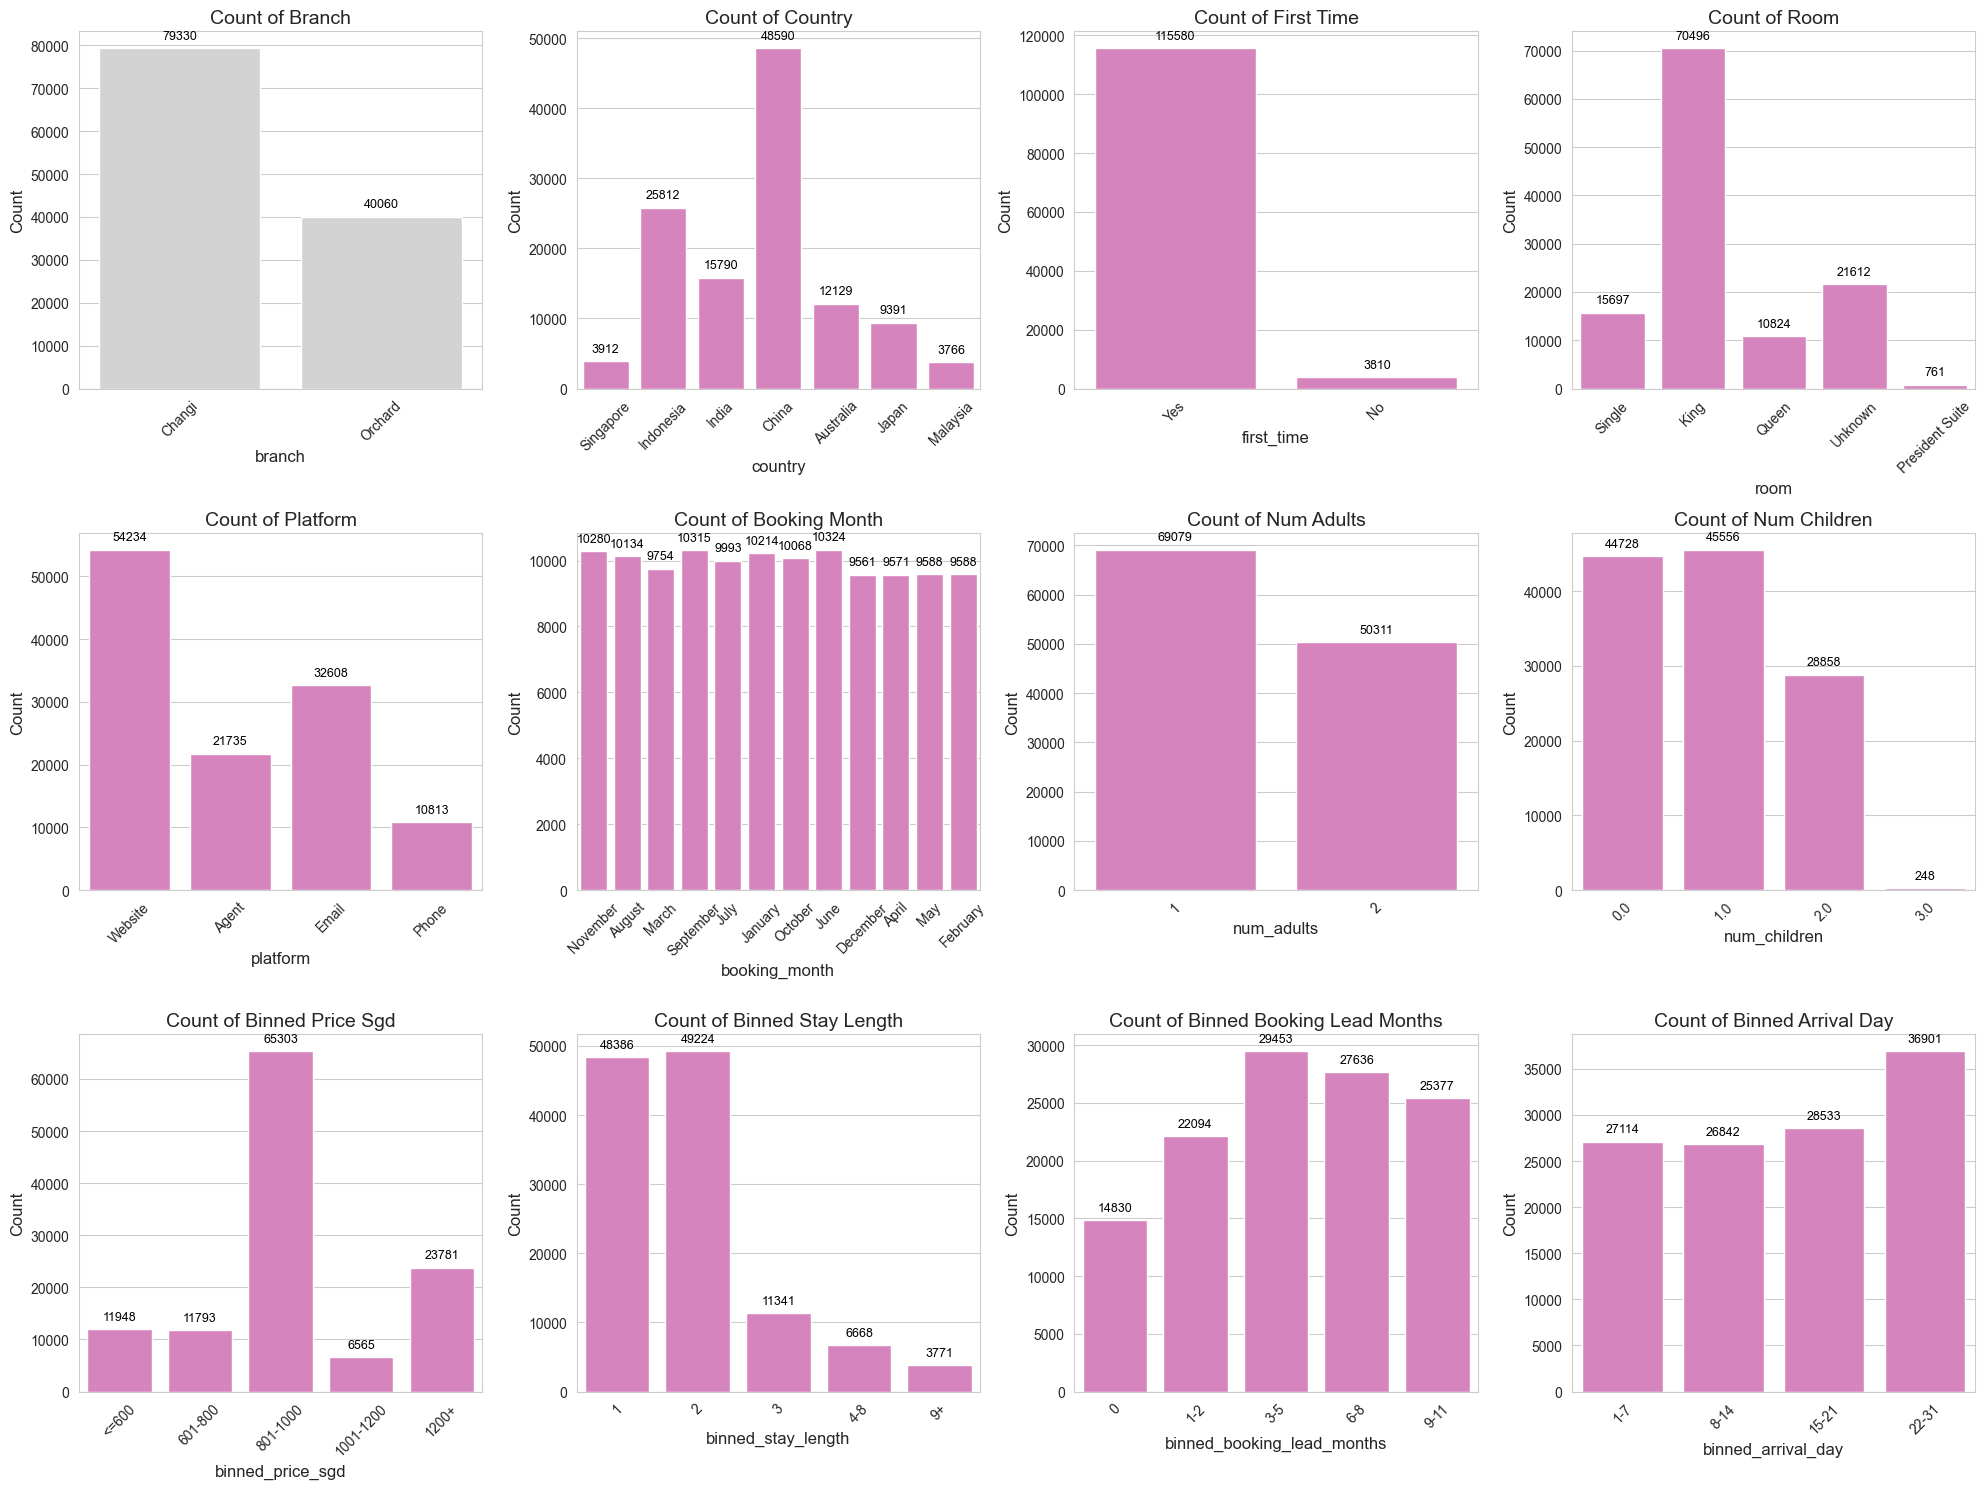

In [23]:
# Set the style
sns.set_style('whitegrid')

PLOT_FEATURES = [
    ('branch', 'lightgrey'),
    ('country', 'tab:pink'),
    ('first_time', 'tab:pink'),
    ('room', 'tab:pink'),
    ('platform', 'tab:pink'),
    ('booking_month', 'tab:pink'),
    ('num_adults', 'tab:pink'),
    ('num_children', 'tab:pink'),
    ('binned_price_sgd', 'tab:pink'),
    ('binned_stay_length', 'tab:pink'),
    ('binned_booking_lead_months', 'tab:pink'),
    ('binned_arrival_day', 'tab:pink')
]


def _plot_countplots(df, features, axes_col_max, figsize_x=20, figsize_y=15):
    '''Helper function to plot countplots for categorical features with subplot management.

    Parameters:
        - df (pd.DataFrame): The cleaned DataFrame to plot.
        - features (list): List of (feature, color) tuples to plot.
        - axes_col_max (int): Maximum number of columns for subplots.
        - figsize_x (int): Width of the figure.
        - figsize_y (int): Height of the figure.
    '''
    axes_row_max = (len(features) + axes_col_max - 1) // axes_col_max
    fig, axes = plt.subplots(axes_row_max, axes_col_max, figsize=(figsize_x, figsize_y), sharey=False)

    axes_row = 0
    axes_col = 0
    for feature, color in features:
        sns.countplot(data=df, x=feature, ax=axes[axes_row, axes_col], color=color)
        axes[axes_row, axes_col].set_title(f"Count of {feature.replace('_', ' ').title()}", fontsize=14)
        axes[axes_row, axes_col].set_xlabel(feature, fontsize=12)
        axes[axes_row, axes_col].set_ylabel("Count", fontsize=12)
        axes[axes_row, axes_col].tick_params(axis='x', labelrotation=45)

        axes_col += 1
        if axes_col == axes_col_max:
            axes_col = 0
            axes_row += 1

    for ax in axes.flatten():
        for p in ax.patches:
            count = int(p.get_height())
            ax.annotate(f'{count}', (p.get_x() + p.get_width() / 2., p.get_height()),
                        ha='center', va='center', fontsize=9, color='black', xytext=(0, 9),
                        textcoords='offset points')

    plt.tight_layout()
    plt.show()


_plot_countplots(df_cleaned, PLOT_FEATURES, axes_col_max=4, figsize_x=20, figsize_y=15)

**Interpreting the Count Plots**

**Strong concentration in a few categories**

* `branch` is uneven: Changi handles 79,330 bookings against Orchard's 40,060, so Changi supplies roughly two thirds of the data.
* `country` is dominated by China (48,590), followed by Indonesia (25,812), India (15,790) and Australia (12,129). Japan (9,391), Singapore (3,912) and Malaysia (3,766) form a small tail.
* `first_time` is almost entirely returning-guest data: 115,580 bookings are first-time guests and only 3,810 are not. The minority group is small but large enough to keep.
* `room` is concentrated in King (70,496), with Single (15,697), Queen (10,824), President Suite (761) and the imputed Unknown group (21,612).
* `platform` is spread across Website (54,234), Email (32,608), Agent (21,735) and Phone (10,813), with no single channel close to disappearing.

**Balanced or near-uniform features**

* `num_adults` is concentrated at one or two adults, with the word-form entries successfully mapped into the same categories.
* `num_children` is split fairly evenly between zero, one and two children, with three children rare.
* `binned_price_sgd` is roughly bell-shaped around 801-1000 SGD, while `binned_stay_length` is dominated by one- and two-night stays.
* `booking_month` is close to uniform across the year, which means seasonality in the no-show rate is a genuine behavioural signal rather than a sample-size artefact.

The main implication is that any model comparison must handle high-cardinality `country` and the small `first_time` minority carefully. One-hot encoding with `drop='first'` keeps the feature space manageable, and stratified splitting prevents a validation set that happens to contain no returning guests.

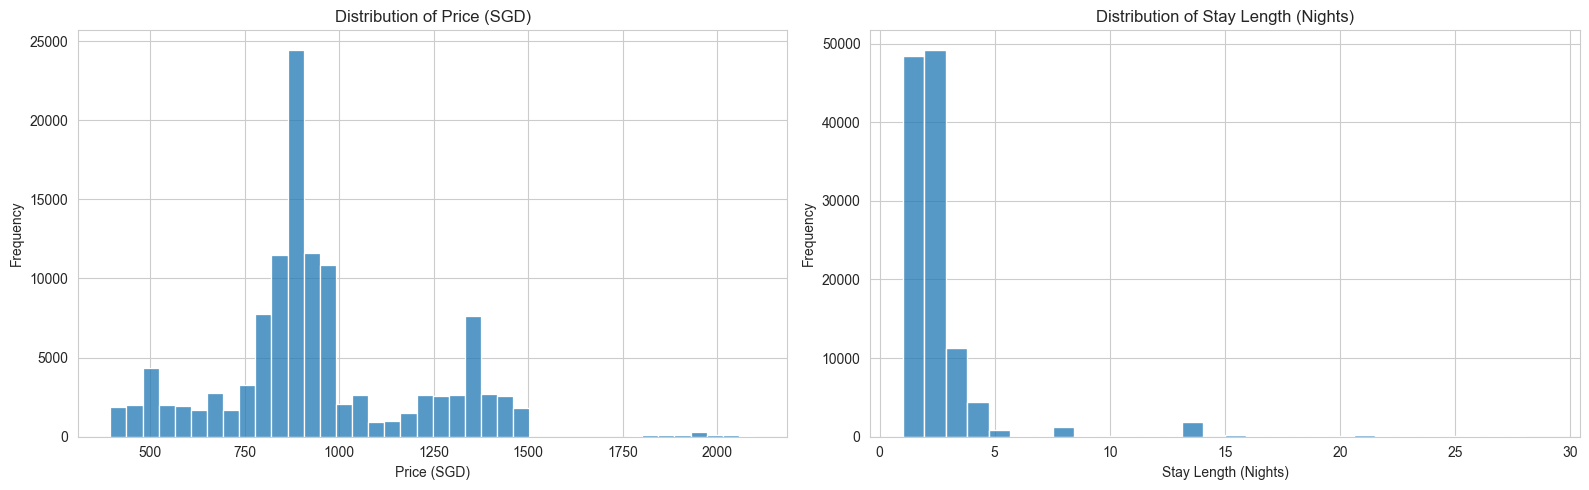

In [24]:
# Numeric distributions for price and stay length
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

sns.histplot(df_cleaned['price_sgd'], bins=40, ax=axes[0], color='tab:blue')
axes[0].set_title('Distribution of Price (SGD)')
axes[0].set_xlabel('Price (SGD)')
axes[0].set_ylabel('Frequency')

sns.histplot(df_cleaned['stay_length'], bins=30, ax=axes[1], color='tab:blue')
axes[1].set_title('Distribution of Stay Length (Nights)')
axes[1].set_xlabel('Stay Length (Nights)')
axes[1].set_ylabel('Frequency')

plt.tight_layout()
plt.show()

**Interpreting the Numeric Distributions**

`price_sgd` is a broad, slightly right-skewed distribution centred around 900 SGD after currency conversion. The minimum is roughly 394 SGD and the maximum about 2,100 SGD, so no extreme outliers need special treatment. Because the scale is much larger than the other numeric features, it must be standardised before distance-based models such as KNN.

`stay_length` is heavily concentrated at one and two nights, with a thin tail up to 29 nights. The distribution is not normal, which is another reason to prefer tree-based splits and to treat the variable through both its raw value and the binned view in the bivariate analysis.

## Bivariate Analysis

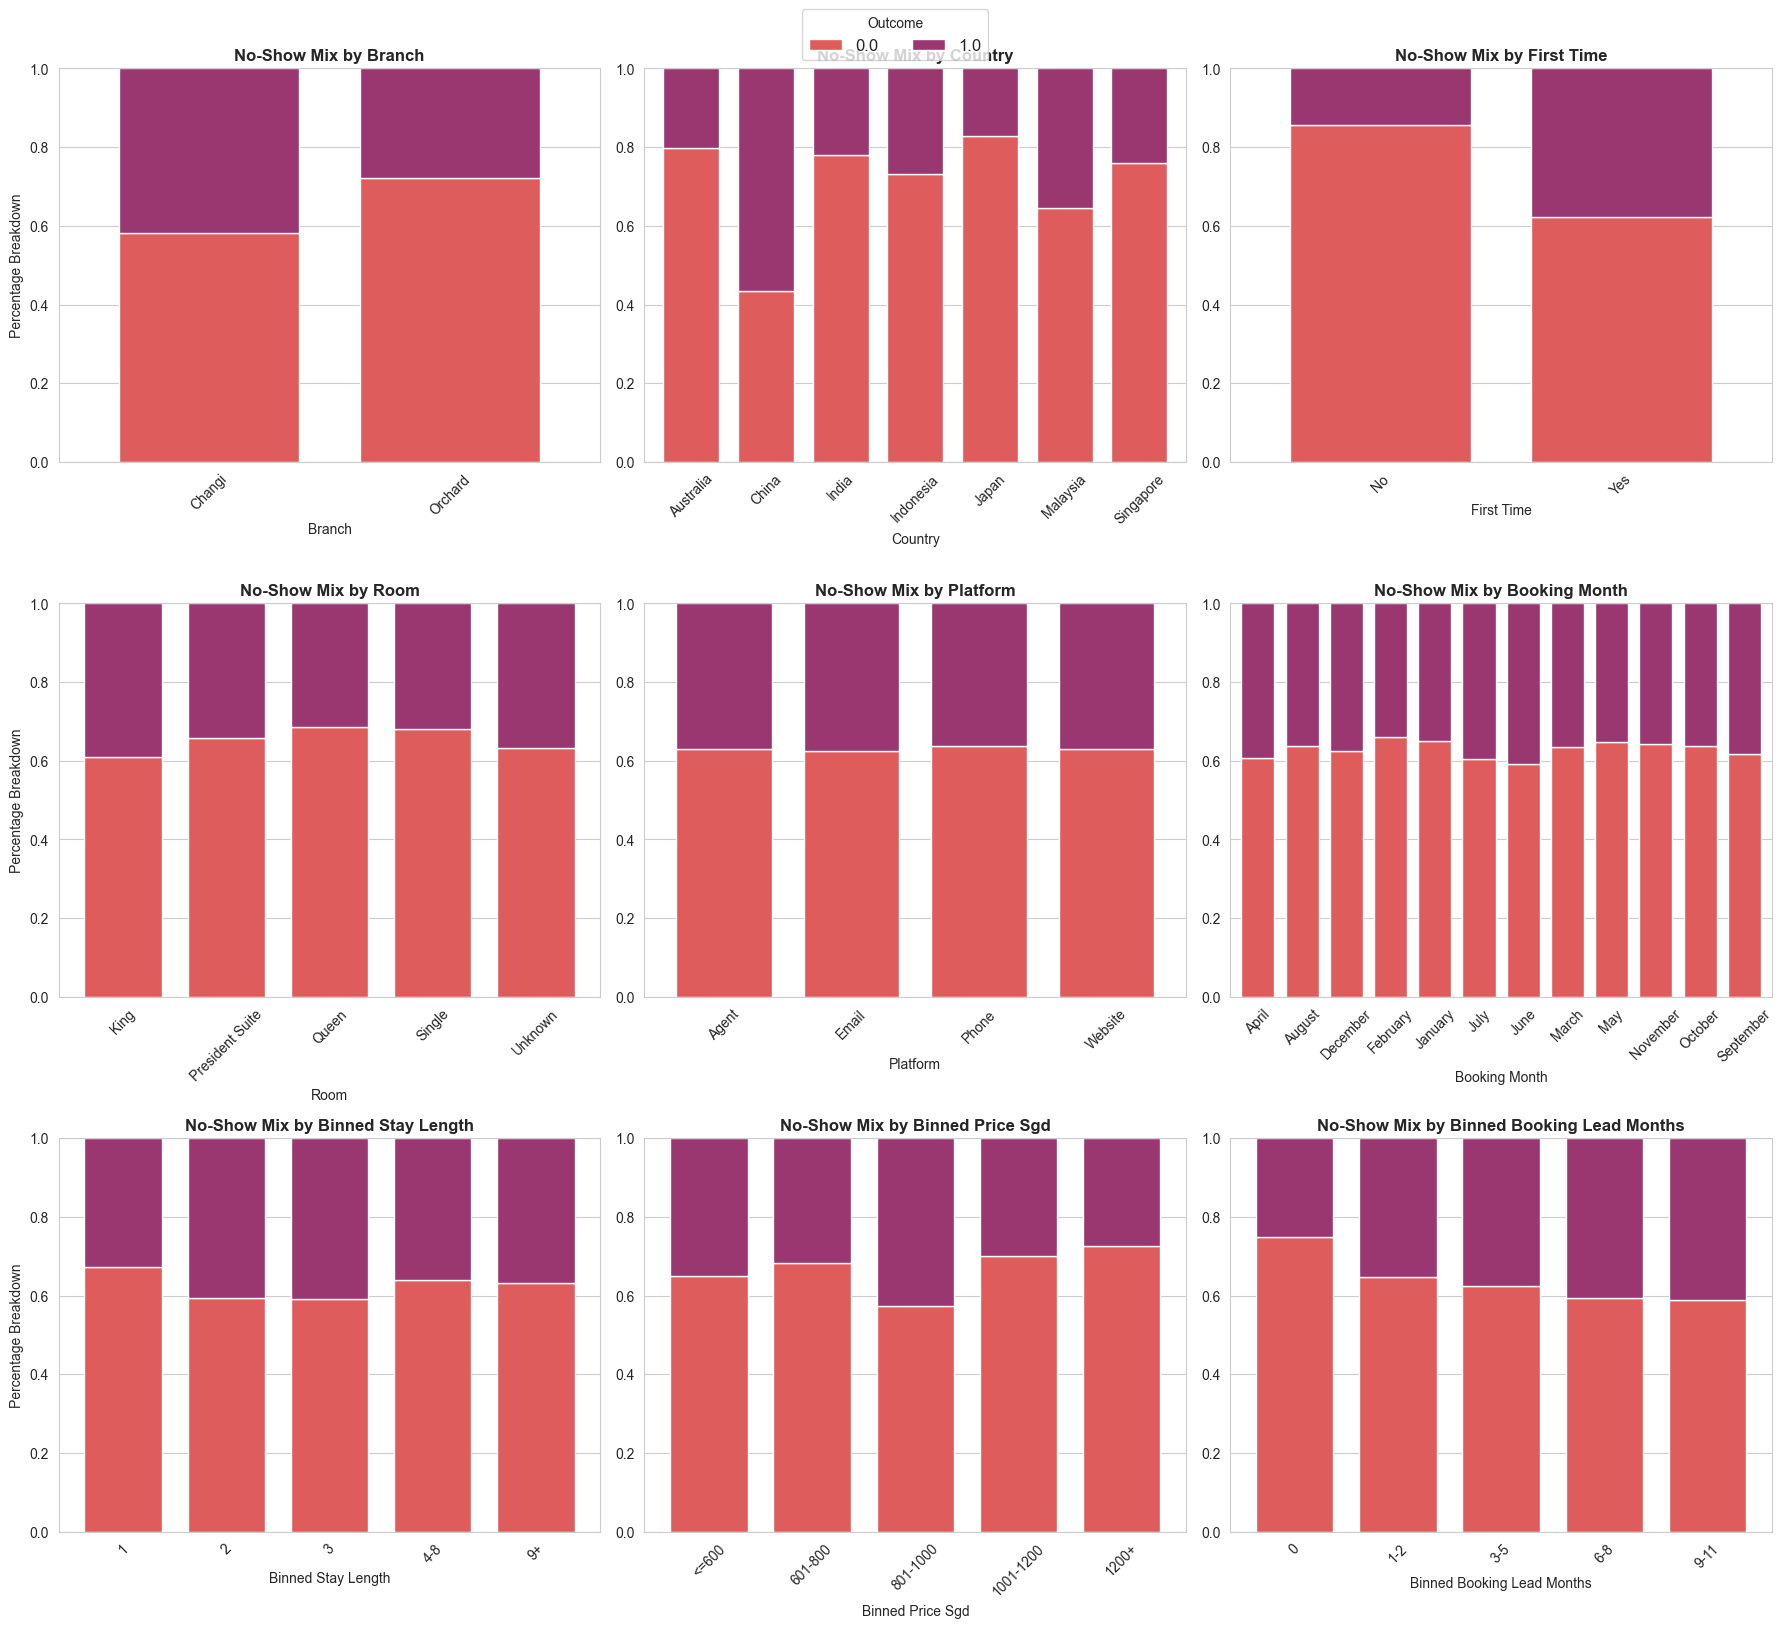

In [25]:
def _plot_normalized_stacked_bars(df, features, axes_col_max=3, figsize_x=15, figsize_y=10):
    """
    Draw 100% normalized stacked bar charts of no-show rates vs. each categorical feature.

    Parameters:
    - df (pd.DataFrame): cleaned dataset.
    - features (list of (str, str)): List of (column_name, color) tuples.
    - axes_col_max (int): Number of columns in the subplot grid.
    - figsize_x, figsize_y (int): Figure dimensions.
    """
    n_features = len(features)
    n_rows = (n_features + axes_col_max - 1) // axes_col_max

    fig, axes = plt.subplots(n_rows, axes_col_max, figsize=(figsize_x, figsize_y), squeeze=False)
    axes = axes.flatten()

    outcome_palette = sns.color_palette('flare', as_cmap=False, n_colors=2)

    for i, (feature, _) in enumerate(features):
        crosstab = pd.crosstab(df[feature], df['no_show'])
        crosstab_pct = crosstab.div(crosstab.sum(axis=1), axis=0)

        crosstab_pct.plot(kind='bar', stacked=True, ax=axes[i], color=outcome_palette, width=0.75)
        axes[i].set_title(f"No-Show Mix by {feature.replace('_', ' ').title()}", fontsize=12, fontweight='bold')
        axes[i].set_xlabel(feature.replace('_', ' ').title(), fontsize=10)
        axes[i].set_ylabel("Percentage Breakdown" if i % axes_col_max == 0 else "", fontsize=10)
        axes[i].set_ylim(0, 1)
        axes[i].get_legend().remove()
        axes[i].tick_params(axis='x', labelrotation=45)

    # Turn off any unused subplots
    for j in range(n_features, len(axes)):
        axes[j].axis('off')

    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, title="Outcome", loc='upper center', bbox_to_anchor=(0.5, 1.02), ncol=2, fontsize=12)

    plt.tight_layout()
    plt.show()


BIVARIATE_FEATURES = [
    ('branch', 'lightgrey'),
    ('country', 'tab:pink'),
    ('first_time', 'tab:pink'),
    ('room', 'tab:pink'),
    ('platform', 'tab:pink'),
    ('booking_month', 'tab:pink'),
    ('binned_stay_length', 'tab:pink'),
    ('binned_price_sgd', 'tab:pink'),
    ('binned_booking_lead_months', 'tab:pink')
]

_plot_normalized_stacked_bars(df_cleaned, BIVARIATE_FEATURES, axes_col_max=3, figsize_x=18, figsize_y=16)

**Interpreting the 100% Normalised Stacked Bars**

**Clear no-show signals**

* **Country** is the strongest categorical signal. Chinese guests have a 56.6% no-show rate, while Japanese guests are at 17.1%. Indonesia, India and Australia sit in between. The gap is large enough that nationality should be a leading feature in every model.
* **Branch** matters: Changi runs at 41.7% no-shows against Orchard's 27.8%. Changi is also the larger branch, so its behaviour dominates the overall rate.
* **First-time guest status** is highly predictive: first-time guests no-show 37.8% of the time, versus 14.5% for returning guests. The minority group is small but behaves very differently, which is why it is worth keeping despite its size.
* **Room type** separates the booking: King rooms run at 39.2%, Queen at 31.4%, Single at 31.9% and President Suite at 34.3%. The imputed Unknown group sits close to the overall average, which is consistent with missingness carrying little information.

**Weak or flat signals**

* **Platform** is essentially flat, with all four channels between 36% and 37%. Booking channel does not explain much on its own.
* **Booking month** has a modest seasonal effect: June is the highest at 40.9% and October the lowest at 36.2%. The difference is real but small compared with country or branch.
* **Stay length** is non-monotonic: one-night stays are the lowest at 32.7%, two- and three-night stays rise to about 41%, and longer stays settle back towards 36%. The engineered duration feature therefore carries signal that the raw day numbers did not.
* **Price** is non-monotonic but strongest in the middle: the 801-1000 SGD band has the highest no-show rate at 42.6%, while both the 601-800 band (31.6%) and the 1200+ band (27.5%) are much lower. Very expensive bookings are the least likely to be abandoned.
* **Booking lead time** has a clear monotonic gradient: same-month bookings no-show 25.2% of the time, rising steadily to 41.2% for bookings made 9-11 months ahead.

The picture is that no-show behaviour is driven mainly by who the guest is, where they booked and which branch they chose, with price and duration adding secondary structure. This supports a model that can combine several categorical splits rather than relying on one linear score.

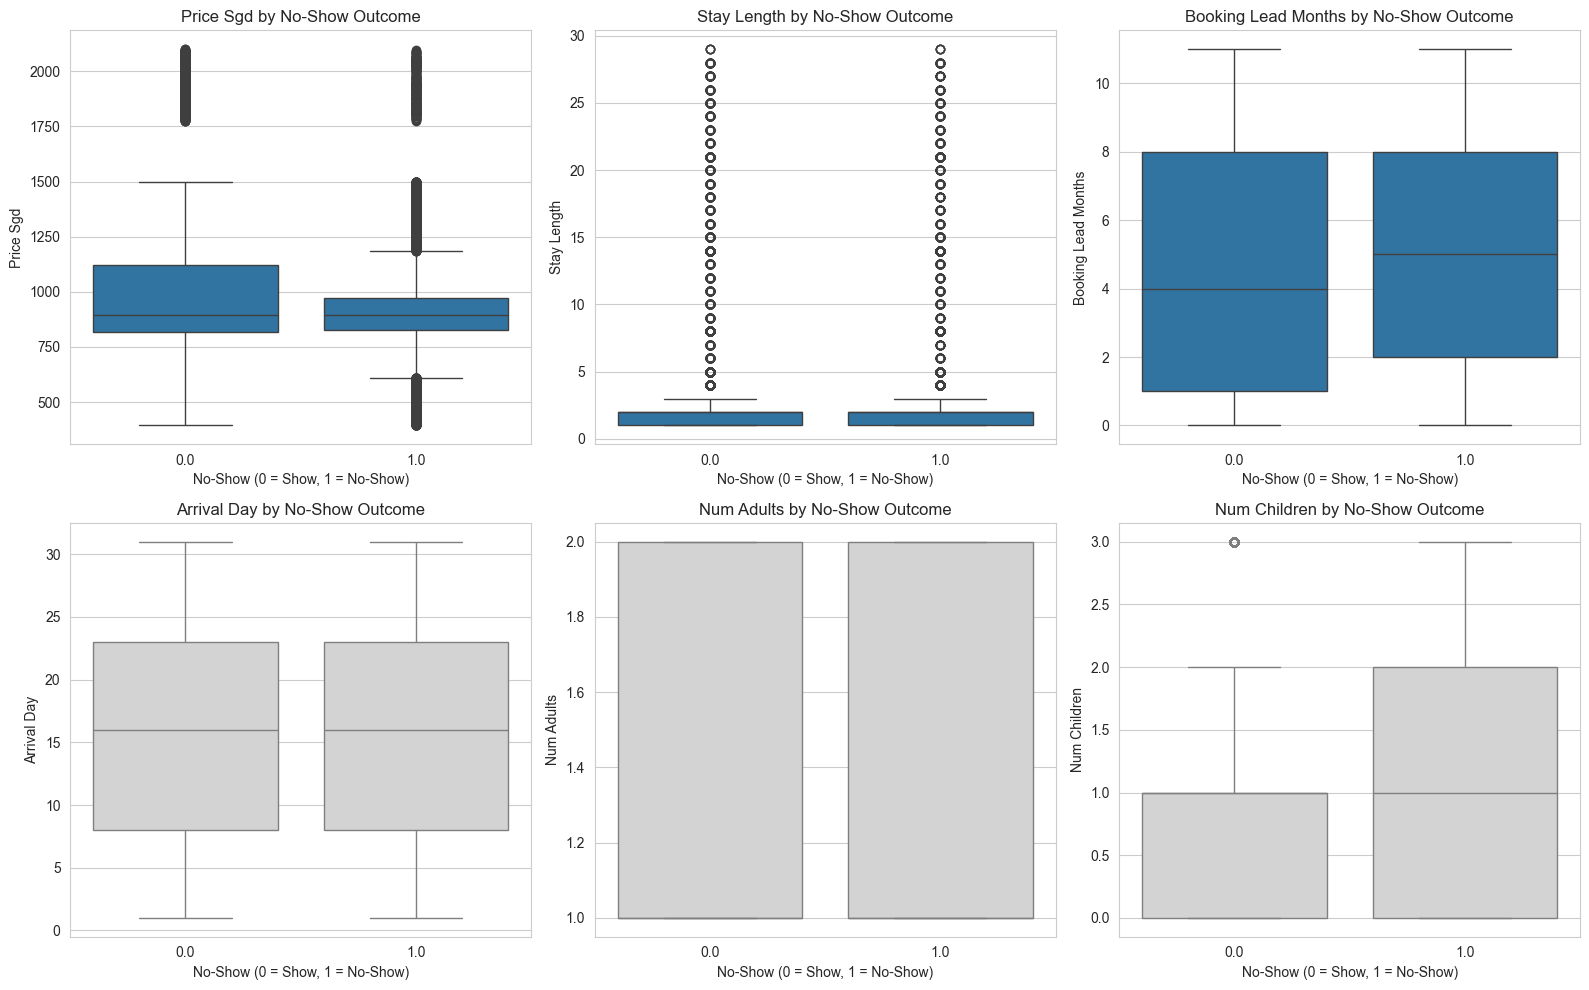

In [26]:
def _plot_boxplot(df, features, axes_col_max=3, figsize_x=15, figsize_y=10):
    """
    Draw boxplots of numeric features against the no-show outcome.

    Parameters:
    - df (pd.DataFrame): cleaned dataset.
    - features (list of (str, str)): List of (column_name, color) tuples.
    - axes_col_max (int): Number of columns in the subplot grid.
    - figsize_x, figsize_y (int): Figure dimensions.
    """
    n_features = len(features)
    n_rows = (n_features + axes_col_max - 1) // axes_col_max

    fig, axes = plt.subplots(n_rows, axes_col_max, figsize=(figsize_x, figsize_y), sharey=False)
    axes = axes.flatten()

    for i, (feature, color) in enumerate(features):
        sns.boxplot(data=df, x='no_show', y=feature, ax=axes[i], color=color)
        axes[i].set_title(f"{feature.replace('_', ' ').title()} by No-Show Outcome")
        axes[i].set_xlabel("No-Show (0 = Show, 1 = No-Show)")
        axes[i].set_ylabel(feature.replace('_', ' ').title())

    for j in range(n_features, len(axes)):
        axes[j].axis('off')

    plt.tight_layout()
    plt.show()


BOXPLOT_FEATURES = [
    ('price_sgd', 'tab:blue'),
    ('stay_length', 'tab:blue'),
    ('booking_lead_months', 'tab:blue'),
    ('arrival_day', 'lightgray'),
    ('num_adults', 'lightgray'),
    ('num_children', 'lightgray')
]

_plot_boxplot(df_cleaned, BOXPLOT_FEATURES, axes_col_max=3, figsize_x=16, figsize_y=10)

**Interpreting the Boxplots**

The boxplots confirm that the numeric features separate the classes only weakly on their own. The median price, stay length and booking lead time are very close for shows and no-shows, and the interquartile boxes overlap almost completely. The arrival day, adult count and child count distributions are similarly flat.

This does not mean the numeric features are useless. It means their effect is conditional: price matters differently by room type, and stay length matters differently by branch. A linear model can only add these effects, while a tree can split on them jointly. The weak marginal separation is also why I expect accuracy in the low 70s rather than a near-perfect classifier, and why ROC AUC is a more informative comparison metric than the boxplot medians.

## Correlation Analysis

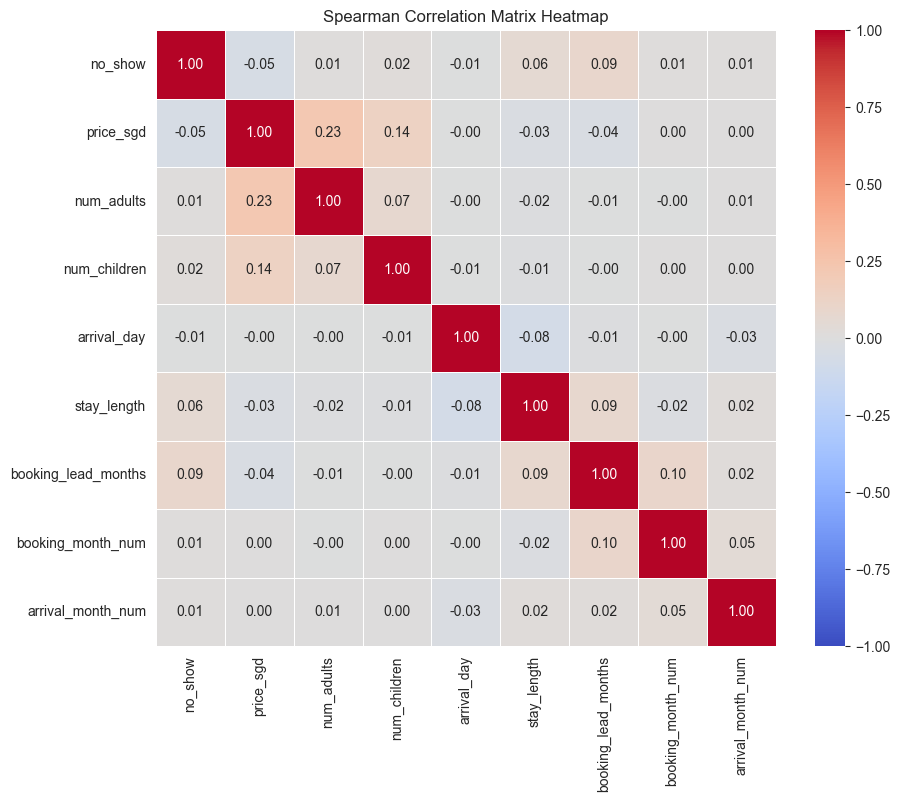

In [27]:
# Spearman correlation on the numeric features and the target
spearman_vars = df_cleaned[[
    'no_show', 'price_sgd', 'num_adults', 'num_children', 'arrival_day',
    'stay_length', 'booking_lead_months', 'booking_month_num', 'arrival_month_num'
]]

spearman_corr = spearman_vars.corr(method='spearman')

plt.figure(figsize=(10, 8))
sns.heatmap(spearman_corr, annot=True, cmap='coolwarm', center=0, vmin=-1, vmax=1,
            linewidths=0.5, fmt='.2f')
plt.title('Spearman Correlation Matrix Heatmap')
plt.show()

**Interpreting the Spearman Correlation Results**

All correlations with `no_show` are small. The strongest is `booking_lead_months` at about +0.09, followed by `stay_length` at about +0.06 and `price_sgd` at about -0.05. The month numbers, arrival day and passenger counts are all below 0.02. No numeric feature on its own explains much of the outcome.

This is consistent with the boxplots: the predictive signal lives mainly in the categorical splits (country, branch, first-time status, room), which do not appear in a numeric correlation matrix. It is also why a multivariable model is necessary; a single correlation cannot capture the interaction between, say, branch and room type.

Pearson correlation was omitted in favour of Spearman because the target is binary and the numeric features are not normally distributed. Pearson assumes continuous, roughly normal variables and measures linear association; Spearman ranks the observations and measures monotonic association, which is the more honest summary for a 0/1 outcome and skewed price and duration variables. Even so, these coefficients should be read as descriptive, not as effect sizes from a causal model.

## Data Splitting

I keep only the features identified in the EDA and split the data into training (80%), validation (10%) and test (10%) sets. Both splits are stratified on `no_show` so every subset preserves the 63/37 class balance.

The validation set is used for model comparison and hyperparameter tuning; the test set is held back until the final model is chosen.

In [28]:
# Separate the data into features and target
X = df_cleaned.drop(columns='no_show')
y = df_cleaned['no_show'].astype(int)

# Only keep selected columns for X
numerical_features = [
    'price_sgd', 'num_adults', 'num_children', 'arrival_day',
    'stay_length', 'booking_lead_months', 'booking_month_num', 'arrival_month_num'
]
nominal_features = ['branch', 'country', 'first_time', 'room', 'platform']
selected_cols = numerical_features + nominal_features

X = X[selected_cols]

print("Selected features:", selected_cols)
print("Feature matrix shape:", X.shape)

# Split into training (80%) and test-validation (20%) sets, stratified on the target
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Split the test-validation set (20%) into validation (10%) and test (10%) sets
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp
)

print()
print("Training set shape:", X_train.shape, y_train.shape)
print("Validation set shape:", X_val.shape, y_val.shape)
print("Test set shape:", X_test.shape, y_test.shape)
print()
print("Training class distribution:")
print(y_train.value_counts(normalize=True).round(4))
print("Validation class distribution:")
print(y_val.value_counts(normalize=True).round(4))

Selected features: ['price_sgd', 'num_adults', 'num_children', 'arrival_day', 'stay_length', 'booking_lead_months', 'booking_month_num', 'arrival_month_num', 'branch', 'country', 'first_time', 'room', 'platform']
Feature matrix shape: (119390, 13)

Training set shape: (95512, 13) (95512,)
Validation set shape: (11939, 13) (11939,)
Test set shape: (11939, 13) (11939,)

Training class distribution:
no_show
0    0.6296
1    0.3704
Name: proportion, dtype: float64
Validation class distribution:
no_show
0    0.6295
1    0.3705
Name: proportion, dtype: float64


Stratified splitting is necessary because the no-show rate is 37%, not 50%. A purely random split could produce a validation set with a noticeably different positive rate, which would make model comparisons noisy. Stratifying keeps the 63/37 ratio fixed and makes the validation and test scores comparable across models.

I deliberately do not resample the training data. The minority class has more than 44,000 examples, so the models have ample positive cases to learn from, and preserving the natural prior keeps predicted probabilities interpretable. That matters for an overbooking policy, where the cost of a wrong decision depends on the actual probability rather than on a balanced 50/50 world.

## Feature Scaling and Encoding

I standardise the eight numerical features with `StandardScaler` so that price (hundreds to thousands of SGD) does not dominate distance-based calculations in KNN, and so that logistic regression coefficients are comparable. The five nominal features are one-hot encoded with `drop='first'` to avoid perfect multicollinearity, and `handle_unknown='ignore'` protects inference if a future booking contains an unseen country or platform. `remainder='drop'` ensures the binned analysis columns and the raw text columns never leak into the model.

In [29]:
# Numerical transformer
numerical_transformer = Pipeline(steps=[
    ('scaler', StandardScaler())
])

# Nominal transformer: drop first to avoid multicollinearity
nominal_transformer = Pipeline(steps=[
    ('onehot', OneHotEncoder(drop='first', handle_unknown='ignore'))
])

# Combine transformers into a single ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_transformer, numerical_features),
        ('nom', nominal_transformer, nominal_features)
    ],
    remainder='drop',
    n_jobs=-1
)

print("Preprocessor created with", len(numerical_features), "numerical and",
      len(nominal_features), "nominal features.")

Preprocessor created with 8 numerical and 5 nominal features.


## Dummy Classifier

Before fitting any real model, I establish a baseline with a stratified dummy classifier. It predicts classes according to the training distribution, so it represents random guessing that still respects the 63/37 prior. Any useful model must beat this comfortably on F1 and ROC AUC.

In [30]:
# Metric evaluation table data
data_class = [['Model', 'Accuracy', 'Precision', 'Recall', 'F1 Score', 'ROC AUC']]

# Stratified dummy classifier as the naive baseline
dummy_clf_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', DummyClassifier(strategy='stratified', random_state=42))
])
dummy_clf_pipeline.fit(X_train, y_train)

y_val_pred_dummy = dummy_clf_pipeline.predict(X_val)
y_val_pred_proba_dummy = dummy_clf_pipeline.predict_proba(X_val)[:, 1]

val_acc_dummy = accuracy_score(y_val, y_val_pred_dummy)
val_prec_dummy = precision_score(y_val, y_val_pred_dummy, zero_division=0)
val_rec_dummy = recall_score(y_val, y_val_pred_dummy, zero_division=0)
val_f1_dummy = f1_score(y_val, y_val_pred_dummy, zero_division=0)
val_auc_dummy = roc_auc_score(y_val, y_val_pred_proba_dummy)

print("Dummy Classifier Metrics:")
print(f'Validation Accuracy:  {val_acc_dummy:.5f}')
print(f'Validation Precision: {val_prec_dummy:.5f}')
print(f'Validation Recall:    {val_rec_dummy:.5f}')
print(f'Validation F1 Score:  {val_f1_dummy:.5f}')
print(f'Validation ROC AUC:   {val_auc_dummy:.5f}')

data_class.append(['Dummy Classifier', val_acc_dummy, val_prec_dummy, val_rec_dummy, val_f1_dummy, val_auc_dummy])

Dummy Classifier Metrics:
Validation Accuracy:  0.54058
Validation Precision: 0.37737
Validation Recall:    0.36943
Validation F1 Score:  0.37336
Validation ROC AUC:   0.50537


The dummy classifier scores about 0.54 accuracy, 0.377 precision, 0.369 recall, 0.373 F1 and 0.505 ROC AUC. Its accuracy is close to the 0.534 expected from drawing randomly from a 63/37 prior, so it is essentially guessing while respecting the class mix. This confirms that accuracy alone would be misleading: the dummy is only about 0.19 below the real models on accuracy, but about 0.21 below them on F1. F1 and ROC AUC are the metrics that will separate real models from this baseline.

## Logistic Regression

In [31]:
# Logistic Regression pipeline
log_reg_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(C=1, solver='liblinear', max_iter=1000, random_state=42))
])
log_reg_pipeline.fit(X_train, y_train)

y_val_pred_lr = log_reg_pipeline.predict(X_val)
y_val_pred_proba_lr = log_reg_pipeline.predict_proba(X_val)[:, 1]

val_acc_lr = accuracy_score(y_val, y_val_pred_lr)
val_prec_lr = precision_score(y_val, y_val_pred_lr, zero_division=0)
val_rec_lr = recall_score(y_val, y_val_pred_lr, zero_division=0)
val_f1_lr = f1_score(y_val, y_val_pred_lr, zero_division=0)
val_auc_lr = roc_auc_score(y_val, y_val_pred_proba_lr)

print("Logistic Regression Metrics:")
print(f'Validation Accuracy:  {val_acc_lr:.5f}')
print(f'Validation Precision: {val_prec_lr:.5f}')
print(f'Validation Recall:    {val_rec_lr:.5f}')
print(f'Validation F1 Score:  {val_f1_lr:.5f}')
print(f'Validation ROC AUC:   {val_auc_lr:.5f}')

data_class.append(['Logistic Regression', val_acc_lr, val_prec_lr, val_rec_lr, val_f1_lr, val_auc_lr])

Logistic Regression Metrics:
Validation Accuracy:  0.72527
Validation Precision: 0.66503
Validation Recall:    0.52069
Validation F1 Score:  0.58407
Validation ROC AUC:   0.74876


In [32]:
# Inspect the largest logistic regression coefficients on the standardised feature scale
feature_names = preprocessor.get_feature_names_out()
coefficients = log_reg_pipeline.named_steps['classifier'].coef_[0]
coef_series = pd.Series(coefficients, index=feature_names).sort_values()

print("Most negative coefficients (lower no-show probability):")
print(coef_series.head(8))
print()
print("Most positive coefficients (higher no-show probability):")
print(coef_series.tail(8))

Most negative coefficients (lower no-show probability):
nom__branch_Orchard      -0.727746
nom__country_Japan       -0.473688
nom__country_India       -0.100509
num__price_sgd           -0.059757
nom__platform_Phone      -0.037041
nom__room_Single         -0.016339
num__arrival_month_num   -0.010871
num__arrival_day         -0.005780
dtype: float64

Most positive coefficients (higher no-show probability):
nom__room_Queen              0.086076
num__stay_length             0.096701
num__booking_lead_months     0.216451
nom__country_Indonesia       0.224859
nom__room_President Suite    0.472053
nom__country_Malaysia        0.491088
nom__country_China           1.708650
nom__first_time_Yes          1.859067
dtype: float64


Logistic regression reaches about 0.725 validation accuracy and 0.749 ROC AUC, a clear improvement over the dummy baseline. Its recall is the weak point: at the default 0.5 threshold it catches only about 52% of no-shows. The coefficients are directionally sensible. Changi branch, Chinese nationality and first-time status push the no-show probability up, while Japanese nationality and Orchard branch pull it down. The model is well calibrated and easy to explain, which makes it a strong benchmark even if a tree can capture interactions better.

## K-Nearest Neighbours

In [33]:
# K-Nearest Neighbours pipeline
knn_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', KNeighborsClassifier(n_neighbors=5, weights='uniform', metric='minkowski'))
])
knn_pipeline.fit(X_train, y_train)

y_val_pred_knn = knn_pipeline.predict(X_val)
y_val_pred_proba_knn = knn_pipeline.predict_proba(X_val)[:, 1]

val_acc_knn = accuracy_score(y_val, y_val_pred_knn)
val_prec_knn = precision_score(y_val, y_val_pred_knn, zero_division=0)
val_rec_knn = recall_score(y_val, y_val_pred_knn, zero_division=0)
val_f1_knn = f1_score(y_val, y_val_pred_knn, zero_division=0)
val_auc_knn = roc_auc_score(y_val, y_val_pred_proba_knn)

print("K-Nearest Neighbours Metrics:")
print(f'Validation Accuracy:  {val_acc_knn:.5f}')
print(f'Validation Precision: {val_prec_knn:.5f}')
print(f'Validation Recall:    {val_rec_knn:.5f}')
print(f'Validation F1 Score:  {val_f1_knn:.5f}')
print(f'Validation ROC AUC:   {val_auc_knn:.5f}')

data_class.append(['K-Nearest Neighbours', val_acc_knn, val_prec_knn, val_rec_knn, val_f1_knn, val_auc_knn])

K-Nearest Neighbours Metrics:
Validation Accuracy:  0.70148
Validation Precision: 0.61329
Validation Recall:    0.52566
Validation F1 Score:  0.56611
Validation ROC AUC:   0.71497


With five neighbours, KNN reaches about 0.70 accuracy and 0.715 ROC AUC. It is the weakest of the three real models. This is expected: the feature space mixes one-hot encoded country and platform columns with scaled numeric variables, and the notion of distance between two bookings is not especially meaningful. The result does not rule KNN out entirely, because the number of neighbours is a strong tuning lever, but the default setting is clearly underperforming.

## Decision Tree Classifier

A single decision tree is the most interpretable non-linear model: each split can be read as a business rule, and the tree can be plotted and inspected. I first fit a deliberately shallow tree with `max_depth=5` so it does not memorise the training data, then compare it against deeper and unpruned trees to justify the pruning choice.

In [34]:
# Decision Tree pipeline
dt_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', DecisionTreeClassifier(criterion='gini', max_depth=5, min_samples_leaf=1, random_state=42))
])
dt_pipeline.fit(X_train, y_train)

y_val_pred_dt = dt_pipeline.predict(X_val)
y_val_pred_proba_dt = dt_pipeline.predict_proba(X_val)[:, 1]

val_acc_dt = accuracy_score(y_val, y_val_pred_dt)
val_prec_dt = precision_score(y_val, y_val_pred_dt, zero_division=0)
val_rec_dt = recall_score(y_val, y_val_pred_dt, zero_division=0)
val_f1_dt = f1_score(y_val, y_val_pred_dt, zero_division=0)
val_auc_dt = roc_auc_score(y_val, y_val_pred_proba_dt)

print("Decision Tree Metrics:")
print(f'Validation Accuracy:  {val_acc_dt:.5f}')
print(f'Validation Precision: {val_prec_dt:.5f}')
print(f'Validation Recall:    {val_rec_dt:.5f}')
print(f'Validation F1 Score:  {val_f1_dt:.5f}')
print(f'Validation ROC AUC:   {val_auc_dt:.5f}')

data_class.append(['Decision Tree', val_acc_dt, val_prec_dt, val_rec_dt, val_f1_dt, val_auc_dt])

Decision Tree Metrics:
Validation Accuracy:  0.73524
Validation Precision: 0.69415
Validation Recall:    0.51006
Validation F1 Score:  0.58804
Validation ROC AUC:   0.75827


In [35]:
# Compare pruned versus deeper trees to justify the depth choice
pruning_results = []

for depth in [4, 5, 6, 8, None]:
    tree_pipeline = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', DecisionTreeClassifier(criterion='gini', max_depth=depth, random_state=42))
    ])
    tree_pipeline.fit(X_train, y_train)
    y_pred = tree_pipeline.predict(X_val)
    y_proba = tree_pipeline.predict_proba(X_val)[:, 1]
    pruning_results.append([
        'None (unpruned)' if depth is None else depth,
        accuracy_score(y_val, y_pred),
        f1_score(y_val, y_pred, zero_division=0),
        roc_auc_score(y_val, y_proba)
    ])

pruning_df = pd.DataFrame(pruning_results, columns=['Max Depth', 'Accuracy', 'F1 Score', 'ROC AUC'])
pruning_df

,Max Depth,Accuracy,F1 Score,ROC AUC
0,4,0.733646,0.598079,0.748486
1,5,0.735237,0.588036,0.758271
2,6,0.737499,0.603291,0.763924
3,8,0.735824,0.586848,0.772669
4,None (unpruned),0.701231,0.603358,0.683657


The comparison shows the pruning trade-off clearly. An unpruned tree grows until every leaf is pure, which fits noise and collapses to about 0.701 validation accuracy despite much greater complexity. Increasing depth from 4 to 6 improves F1, but depth 8 keeps improving ROC AUC while F1 falls, and none of the fixed depths beats depth 6 on F1. `max_depth=5` is therefore a defensible baseline: it captures the main country, branch and first-time splits without memorising individual bookings. The grid search later explores depths 4, 6, 8 and unpruned, and resolves the trade-off by keeping an unbounded depth while requiring at least 10 bookings per leaf - a form of pre-pruning that prevents small, noisy splits.

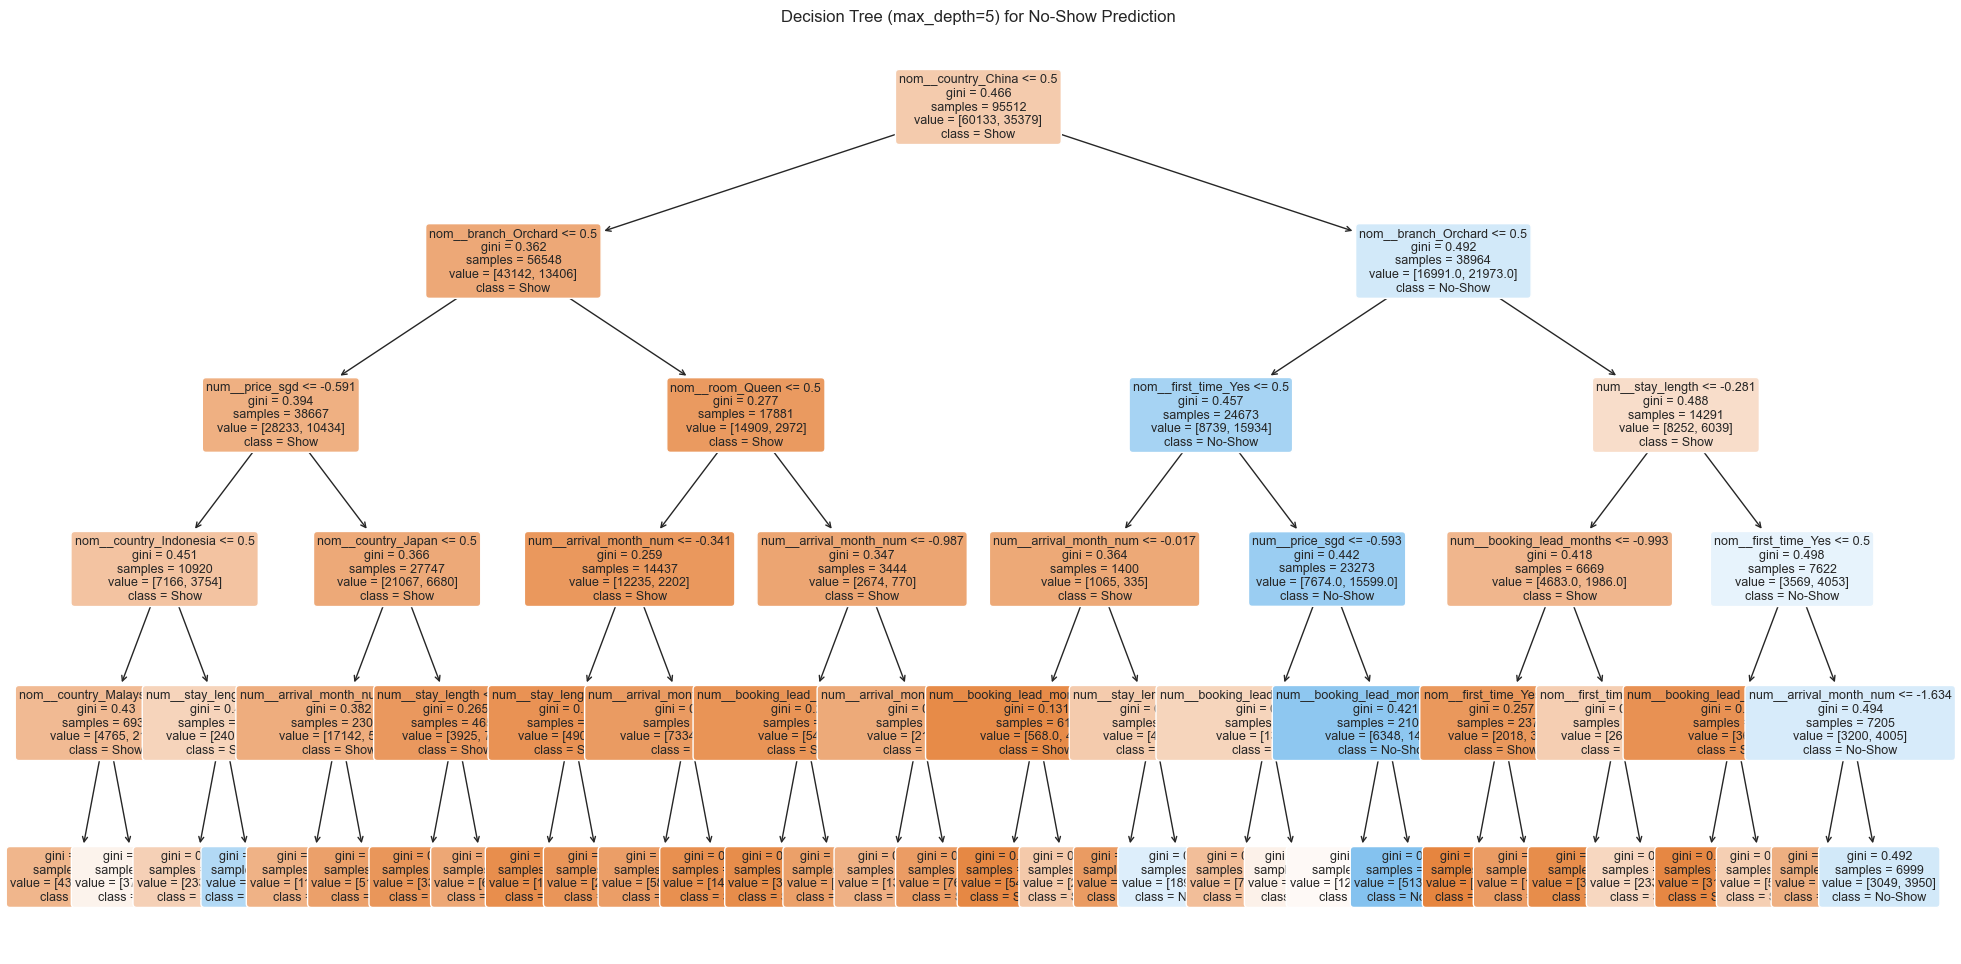

In [36]:
# Plot the shallow decision tree with readable feature names
feature_names = preprocessor.get_feature_names_out()

plt.figure(figsize=(24, 12))
plot_tree(
    dt_pipeline.named_steps['classifier'],
    feature_names=feature_names,
    class_names=['Show', 'No-Show'],
    filled=True,
    rounded=True,
    fontsize=9
)
plt.title('Decision Tree (max_depth=5) for No-Show Prediction')
plt.show()

The tree plot shows the first split separating bookings by country, then by branch and first-time status, with price and stay length appearing further down. This ordering matches the bivariate analysis: country and branch carry the largest differences in no-show rate. The readable rules are a practical advantage for the hotel chain, because staff can understand why a booking is flagged rather than receiving an unexplained score.

## Confusion Matrix and Precision-Recall Curve

The confusion matrix translates the metrics into operational outcomes. For this problem, a false negative is a no-show the model failed to flag: the room is left empty without a backup plan. A false positive is a show that was flagged as high risk: the hotel may hold or resell a room that the guest actually intended to use. The relative cost of these two errors drives the choice of decision threshold.

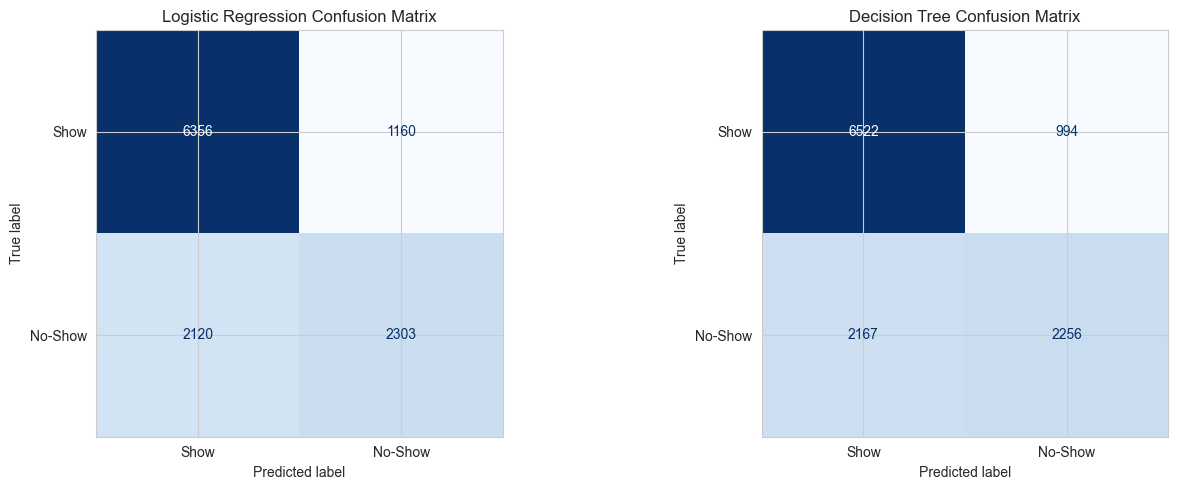

In [37]:
# Confusion matrices for logistic regression and the decision tree
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ConfusionMatrixDisplay.from_estimator(
    log_reg_pipeline, X_val, y_val,
    display_labels=['Show', 'No-Show'], cmap='Blues', ax=axes[0], colorbar=False
)
axes[0].set_title('Logistic Regression Confusion Matrix')

ConfusionMatrixDisplay.from_estimator(
    dt_pipeline, X_val, y_val,
    display_labels=['Show', 'No-Show'], cmap='Blues', ax=axes[1], colorbar=False
)
axes[1].set_title('Decision Tree Confusion Matrix')

plt.tight_layout()
plt.show()

Both models make the same kind of error: they are conservative about predicting a no-show. The off-diagonal cell for missed no-shows (bottom-left) is larger than the cell for false alarms (top-right). In business terms, the models are better at protecting genuine guests from being wrongly denied than at catching every empty room. That is a reasonable default when the cost of falsely denying a room is high, but it also means the hotel still absorbs a substantial share of no-shows.

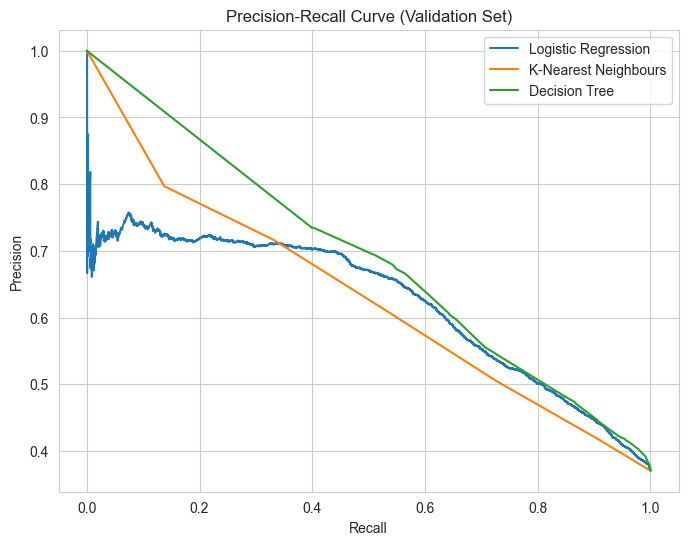

In [38]:
# Precision-recall curves for all three baseline models
plt.figure(figsize=(8, 6))

for name, proba in [
    ('Logistic Regression', y_val_pred_proba_lr),
    ('K-Nearest Neighbours', y_val_pred_proba_knn),
    ('Decision Tree', y_val_pred_proba_dt)
]:
    precision, recall, _ = precision_recall_curve(y_val, proba)
    plt.plot(recall, precision, label=f'{name}')

plt.title('Precision-Recall Curve (Validation Set)')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.legend()
plt.show()

The precision-recall curves sit well above the 37% no-show base rate, which confirms that all three models rank bookings better than chance. Logistic regression and the decision tree are close, with the tree slightly ahead in the high-recall region. KNN trails both across most of the curve.

The trade-off is visible: at low recall, precision is high because only the most obvious no-shows are flagged; as recall increases, precision falls as the model starts flagging borderline bookings. A hotel that wants to catch most no-shows must accept many false alarms, and the curve shows exactly how much precision it would give up.

#### Baseline Model Comparison

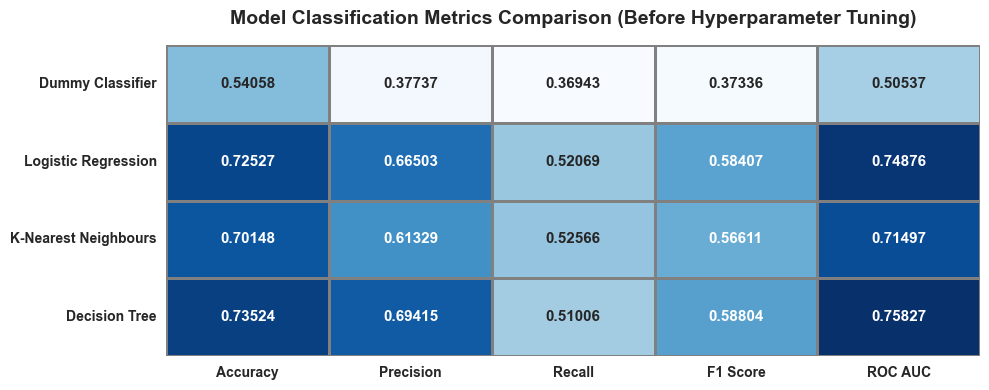

In [39]:
# Convert the metric table to a DataFrame and visualise it
df_metrics = pd.DataFrame(data_class[1:], columns=data_class[0])
df_metrics.set_index('Model', inplace=True)

plt.figure(figsize=(10, 4))
sns.heatmap(
    df_metrics,
    annot=True,
    fmt='.5f',
    cmap='Blues',
    cbar=False,
    linewidths=1,
    linecolor='gray',
    annot_kws={'size': 11, 'weight': 'bold'}
)
plt.title('Model Classification Metrics Comparison (Before Hyperparameter Tuning)', fontsize=14, pad=15, weight='bold')
plt.xticks(rotation=0, weight='bold')
plt.yticks(rotation=0, weight='bold')
plt.xlabel('')
plt.ylabel('')
plt.tight_layout()
plt.show()

The baseline comparison is consistent across metrics. The dummy classifier is bounded by the class prior and contributes nothing beyond accuracy. Logistic regression and the shallow decision tree both reach about 0.73 accuracy, with F1 around 0.58 and ROC AUC around 0.75. The tree has a slight edge in precision, while logistic regression has slightly better recall. KNN is clearly behind at about 0.70 accuracy and 0.715 ROC AUC.

The gap between the dummy and the real models is the proof of concept: there is learnable signal in the booking attributes. The remaining question is whether tuning can widen the gap and whether the tree's interactions justify its extra complexity.

## Grid CV Search

I tune all three model families with `GridSearchCV`, using 5-fold cross-validation and F1 for the positive (no-show) class as the scoring metric. F1 balances precision and recall and is more appropriate than accuracy when the classes are 63/37. The grids are deliberately compact so the search remains tractable on 95k training rows.

In [40]:
# Hyperparameter grids
lr_param_grid = {
    'classifier__C': [0.01, 0.1, 1, 10],
    'classifier__solver': ['liblinear'],
    'classifier__max_iter': [1000]
}

knn_param_grid = {
    'classifier__n_neighbors': [5, 15, 31],
    'classifier__weights': ['uniform', 'distance'],
    'classifier__metric': ['euclidean', 'manhattan']
}

dt_param_grid = {
    'classifier__criterion': ['gini', 'entropy'],
    'classifier__max_depth': [4, 6, 8, None],
    'classifier__min_samples_leaf': [1, 10]
}

# Create the tuning pipelines
lr_tuning_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(random_state=42))
])

knn_tuning_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', KNeighborsClassifier(n_jobs=-1))
])

dt_tuning_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', DecisionTreeClassifier(random_state=42))
])

# Perform grid search, optimising F1 for the positive class
lr_grid_search = GridSearchCV(lr_tuning_pipeline, lr_param_grid, cv=5, scoring='f1', n_jobs=-1)
lr_grid_search.fit(X_train, y_train)

knn_grid_search = GridSearchCV(knn_tuning_pipeline, knn_param_grid, cv=5, scoring='f1', n_jobs=-1)
knn_grid_search.fit(X_train, y_train)

dt_grid_search = GridSearchCV(dt_tuning_pipeline, dt_param_grid, cv=5, scoring='f1', n_jobs=-1)
dt_grid_search.fit(X_train, y_train)

print("Best Logistic Regression parameters:", lr_grid_search.best_params_)
print("Best KNN parameters:", knn_grid_search.best_params_)
print("Best Decision Tree parameters:", dt_grid_search.best_params_)
print("-" * 50)
print(f"Best Logistic Regression CV F1: {lr_grid_search.best_score_:.5f}")
print(f"Best KNN CV F1:                 {knn_grid_search.best_score_:.5f}")
print(f"Best Decision Tree CV F1:       {dt_grid_search.best_score_:.5f}")

Best Logistic Regression parameters: {'classifier__C': 10, 'classifier__max_iter': 1000, 'classifier__solver': 'liblinear'}
Best KNN parameters: {'classifier__metric': 'manhattan', 'classifier__n_neighbors': 15, 'classifier__weights': 'distance'}
Best Decision Tree parameters: {'classifier__criterion': 'gini', 'classifier__max_depth': None, 'classifier__min_samples_leaf': 10}
--------------------------------------------------
Best Logistic Regression CV F1: 0.57301
Best KNN CV F1:                 0.59714
Best Decision Tree CV F1:       0.61582


In [41]:
# Evaluate the tuned models on the validation set
data_class_tuned = [['Model', 'Accuracy', 'Precision', 'Recall', 'F1 Score', 'ROC AUC']]

for name, search_obj in [
    ('Tuned Logistic Regression', lr_grid_search),
    ('Tuned KNN', knn_grid_search),
    ('Tuned Decision Tree', dt_grid_search)
]:
    best_model = search_obj.best_estimator_
    y_val_pred = best_model.predict(X_val)
    y_val_pred_proba = best_model.predict_proba(X_val)[:, 1]

    val_accuracy = accuracy_score(y_val, y_val_pred)
    val_precision = precision_score(y_val, y_val_pred, zero_division=0)
    val_recall = recall_score(y_val, y_val_pred, zero_division=0)
    val_f1 = f1_score(y_val, y_val_pred, zero_division=0)
    val_roc_auc = roc_auc_score(y_val, y_val_pred_proba)

    print(f"\n{name} Metrics:")
    print(f"Validation Accuracy:  {val_accuracy:.5f}")
    print(f"Validation Precision: {val_precision:.5f}")
    print(f"Validation Recall:    {val_recall:.5f}")
    print(f"Validation F1 Score:  {val_f1:.5f}")
    print(f"Validation ROC AUC:   {val_roc_auc:.5f}")

    data_class_tuned.append([name, val_accuracy, val_precision, val_recall, val_f1, val_roc_auc])


Tuned Logistic Regression Metrics:
Validation Accuracy:  0.72527
Validation Precision: 0.66503
Validation Recall:    0.52069
Validation F1 Score:  0.58407
Validation ROC AUC:   0.74876



Tuned KNN Metrics:
Validation Accuracy:  0.73365
Validation Precision: 0.67346
Validation Recall:    0.54556
Validation F1 Score:  0.60280
Validation ROC AUC:   0.76272

Tuned Decision Tree Metrics:
Validation Accuracy:  0.73515
Validation Precision: 0.66711
Validation Recall:    0.56907
Validation F1 Score:  0.61420
Validation ROC AUC:   0.77087


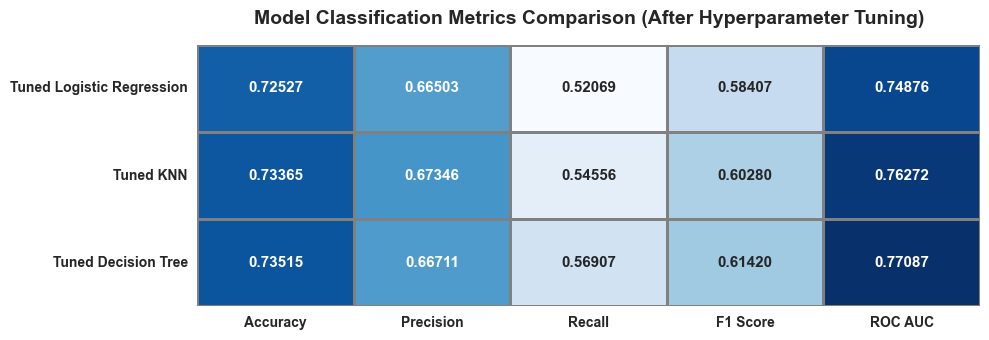

In [42]:
# Display the tuned metrics table
df_metrics_tuned = pd.DataFrame(data_class_tuned[1:], columns=data_class_tuned[0])
df_metrics_tuned.set_index('Model', inplace=True)

plt.figure(figsize=(10, 3.5))
sns.heatmap(
    df_metrics_tuned,
    annot=True,
    fmt='.5f',
    cmap='Blues',
    cbar=False,
    linewidths=1,
    linecolor='gray',
    annot_kws={'size': 11, 'weight': 'bold'}
)
plt.title('Model Classification Metrics Comparison (After Hyperparameter Tuning)', fontsize=14, pad=15, weight='bold')
plt.xticks(rotation=0, weight='bold')
plt.yticks(rotation=0, weight='bold')
plt.xlabel('')
plt.ylabel('')
plt.tight_layout()
plt.show()

In [43]:
# Combined baseline and tuned metric table for the final comparison
df_all_metrics = pd.concat([
    df_metrics.loc[['Dummy Classifier', 'Logistic Regression', 'K-Nearest Neighbours', 'Decision Tree']],
    df_metrics_tuned
])

df_all_metrics.round(5)

,Accuracy,Precision,Recall,F1 Score,ROC AUC
Model,,,,,
Dummy Classifier,0.54058,0.37737,0.36943,0.37336,0.50537
Logistic Regression,0.72527,0.66503,0.52069,0.58407,0.74876
K-Nearest Neighbours,0.70148,0.61329,0.52566,0.56611,0.71497
Decision Tree,0.73524,0.69415,0.51006,0.58804,0.75827
Tuned Logistic Regression,0.72527,0.66503,0.52069,0.58407,0.74876
Tuned KNN,0.73365,0.67346,0.54556,0.60280,0.76272
Tuned Decision Tree,0.73515,0.66711,0.56907,0.61420,0.77087


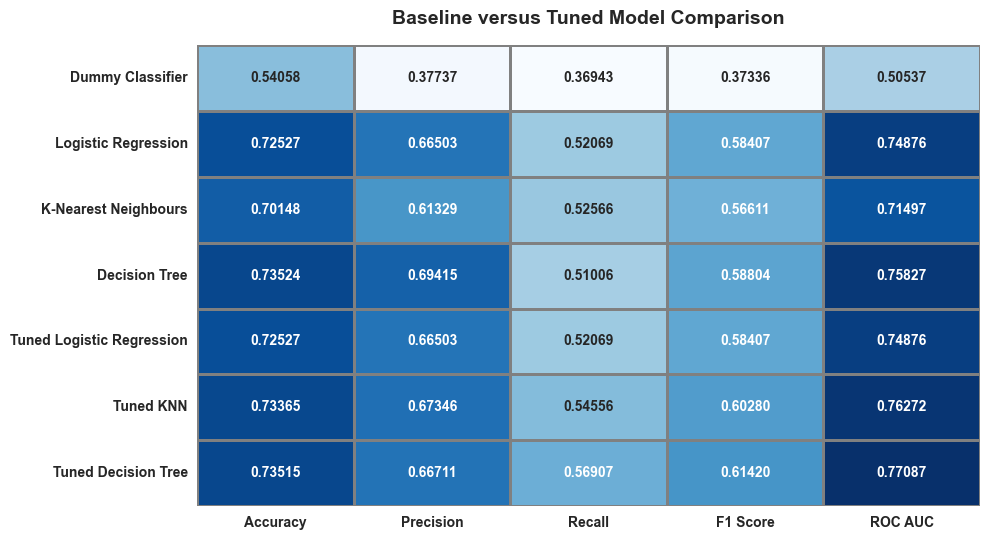

In [44]:
# Heatmap of the combined comparison
plt.figure(figsize=(10, 5.5))
sns.heatmap(
    df_all_metrics,
    annot=True,
    fmt='.5f',
    cmap='Blues',
    cbar=False,
    linewidths=1,
    linecolor='gray',
    annot_kws={'size': 10, 'weight': 'bold'}
)
plt.title('Baseline versus Tuned Model Comparison', fontsize=14, pad=15, weight='bold')
plt.xticks(rotation=0, weight='bold')
plt.yticks(rotation=0, weight='bold')
plt.xlabel('')
plt.ylabel('')
plt.tight_layout()
plt.show()

**Interpreting the Tuned Model Comparison**

Tuning produces a modest but consistent improvement. The tuned decision tree keeps the gini criterion but removes the depth limit, instead requiring at least 10 bookings per leaf. That form of pre-pruning works best: it reaches about 0.735 validation accuracy, 0.614 F1 and 0.771 ROC AUC. Tuned KNN improves markedly by moving to 15 neighbours with distance weighting and Manhattan distance, reaching about 0.734 accuracy and 0.603 F1, which confirms that the default five-neighbour setting was too local. Tuned logistic regression barely changes, because its best regularisation strength is at the edge of the grid; the linear decision boundary is already close to its ceiling.

The tuned tree leads tuned KNN by about 0.011 F1 (0.6142 versus 0.6028) and 0.008 ROC AUC (0.7709 versus 0.7627), and it also edges KNN on recall (0.5691 versus 0.5456). The margin is modest but consistent across every metric, and the two models extract a similar amount of signal. The choice between them should therefore also be checked against operational considerations, not only against the third decimal place.

Two things are also clear from the full table. First, every real model clears the dummy baseline on F1 and ROC AUC, so the features are informative. Second, no model exceeds about 0.62 F1 on validation. The ceiling reflects the data: no-show behaviour has an irreducible random component, and the available attributes describe the booking rather than the guest's changing circumstances.

#### Evaluation on the Held-Out Test Set

The validation set was used for model comparison and tuning. To confirm the choice, I score the selected pipeline once on the 11,939-row test set, which has not been used for any fitting or selection decision.

In [45]:
# Evaluate the selected tuned decision tree once on the held-out test set
best_model = dt_grid_search.best_estimator_
y_test_pred = best_model.predict(X_test)
y_test_pred_proba = best_model.predict_proba(X_test)[:, 1]

test_metrics = pd.DataFrame([[
    'Tuned Decision Tree (test)',
    accuracy_score(y_test, y_test_pred),
    precision_score(y_test, y_test_pred, zero_division=0),
    recall_score(y_test, y_test_pred, zero_division=0),
    f1_score(y_test, y_test_pred, zero_division=0),
    roc_auc_score(y_test, y_test_pred_proba)
]], columns=['Model', 'Accuracy', 'Precision', 'Recall', 'F1 Score', 'ROC AUC'])

test_metrics.set_index('Model', inplace=True)
test_metrics.round(5)

,Accuracy,Precision,Recall,F1 Score,ROC AUC
Model,,,,,
Tuned Decision Tree (test),0.74085,0.67301,0.58412,0.62542,0.77728


The test results follow the same pattern as validation, with accuracy of 0.74085, precision of 0.67301, recall of 0.58412, F1 of 0.62542 and ROC AUC of 0.77728. The small improvement over validation suggests the selected tree is not overfitted to the validation split.

## Final Model Selection and Interpretation

The most suitable model is the **Tuned Decision Tree** (gini criterion, unbounded `max_depth`, `min_samples_leaf=10`). It has the highest validation F1 at 0.61420, the highest validation ROC AUC at 0.77087 and the highest validation accuracy at 0.73515. The test-set evaluation above confirms the choice: the selected pipeline achieves 0.74085 accuracy, 0.67301 precision, 0.58412 recall, 0.62542 F1 and 0.77728 ROC AUC on data it has never seen.

The margin over tuned KNN is about 0.011 F1 and 0.008 ROC AUC, so the tree is ahead but not decisively so. The decision also rests on three practical considerations:

* **Interpretability.** The tuned tree can be printed as a sequence of if-then rules on country, branch, first-time status, room and price. The depth-5 baseline already captures the main splits in a compact form, so the hotel can use a readable approximation where a full explanation is required. KNN cannot offer an equivalent explanation; it only says that a booking resembles other bookings.
* **Operational stability.** KNN stores the entire training set and computes distances at prediction time, which makes inference slower and more memory-intensive as bookings accumulate. The tree stores only split thresholds and is far smaller than the training set, so it can be embedded in the booking system.
* **Threshold control.** Both models output probabilities, so either can support a risk-tiered overbooking policy. The tree's leaf frequencies give directly interpretable risk bands that follow the same country, branch and first-time factors the business already understands, which makes the policy easier to communicate.

**Business interpretation.** The two error types have asymmetric costs. A false negative is a guest who no-shows without being flagged: the room stays empty, and the hotel loses the room revenue it could have recovered by overbooking or by a reminder campaign. A false positive is a guest who was flagged but arrives: if the hotel acts aggressively, it may deny a room to a genuine guest, causing a service failure and reputational damage. The model's default threshold favours precision over recall, which is the conservative choice: it flags only the bookings it is fairly confident about, so the hotel can use those flags for targeted reminders or selective overbooking without routinely punishing reliable guests.

For a practical policy, I would not use a single 0.5 cut-off. The predicted probability can be divided into tiers:
* **High risk (above roughly 0.6):** send a confirmation or deposit request, and consider limited overbooking against these rooms.
* **Medium risk (roughly 0.4 to 0.6):** send a reminder and require a cancellation deadline.
* **Low risk (below 0.4):** no intervention.

The tiers let the hotel tune the intervention to the cost of being wrong. They also acknowledge the model's limits: with F1 around 0.61, a large share of no-shows will still be missed and a share of flagged guests will still arrive. The model is therefore a decision-support tool for allocating attention and overbooking risk, not an automatic denial system.

The ceiling on performance also points to what would improve the model next. The current features describe the booking, not the guest's behaviour after booking. Adding deposit status, prior stay history, cancellation amendments, lead-time changes and channel-level cancellation policies would likely lift F1 more than further tuning of the same three algorithms.